Student : Bhima Fairul Rifqi <br>
ID      : 26/579939/PPA/07301



# AnimalTrack Zebra — YOLO, Dense Farnebäck Optical Flow, and Extended Kalman Filtering

This notebook implements multi-object tracking on AnimalTrack Zebra sequences by combining YOLO detections, dense Farnebäck optical flow, and an image-space constant-turn-rate-and-velocity (CTRV) extended Kalman filter (EKF). Hungarian matching associates detections with persistent track identities. Ground-truth annotations remain outside the inference pipeline and are read only for evaluation and visualization.

**Processing architecture:** sequence decoding → geometric resizing → class-specific YOLO detections → robust Farnebäck displacement → CTRV-EKF prediction and measurement updates → Hungarian assignment → tracked trajectories → evaluation → H.264 video and CSV outputs.

**Data representation:** [AnimalTrack Zebra](https://hengfan2010.github.io/projects/AnimalTrack/download.html) · [AnimalTrack publication](https://arxiv.org/abs/2205.00158). MOT-compatible annotation rows are interpreted as `[frame_id, target_id, x, y, w, h, confidence, class, visibility]`; the parser validates available columns and temporal alignment before evaluation.

## State, motion, and measurement diagnostics

The dense-flow EKF is the primary estimation path. Additional outputs expose intermediate quantities without altering tracker decisions:

- **Motion consistency:** Shi–Tomasi features, pyramidal Lucas–Kanade displacement, forward–backward residuals, median absolute deviation (MAD), and feature replenishment. Sparse flow is computed separately from the Farnebäck measurements.
- **Filter state:** predicted $\hat{\mathbf x}_t^-$ and corrected $\hat{\mathbf x}_t^+$ centers, optical-flow position observations, estimated speed and turning rate, and $2\sigma$ covariance ellipses.
- **Measurement availability:** optional suppression of YOLO detections over a specified frame interval while preserving the underlying image frames and dense optical flow.
- **Reference evaluation:** per-frame matching, localization error, identity continuity, trajectory coverage, and matched-pair RMSE. Reference boxes never initialize or correct the tracker.

A linear constant-velocity state model is displayed for algebraic comparison; the operational multi-target filter uses the nonlinear CTRV transition. No quantitative performance claims are made until the sequence has been processed.


## 1. Nonlinear state-space representation

The state vector is defined in image coordinates as

$$\mathbf{x}_t=[c_x,c_y,v,\theta,\omega,\log w,\log h]^{\mathsf T},$$

where $(c_x,c_y)$ is the bounding-box center, $v$ is speed in pixels per second, $\theta$ is heading, $\omega$ is angular rate, and $(w,h)$ denotes bounding-box dimensions. For $|\omega|>\epsilon$, the CTRV transition is

$$\begin{aligned}
c_x' &=c_x+\tfrac{v}{\omega}[\sin(\theta+\omega\Delta t)-\sin\theta],\\
c_y' &=c_y+\tfrac{v}{\omega}[-\cos(\theta+\omega\Delta t)+\cos\theta],\\
\theta'&=\theta+\omega\Delta t.
\end{aligned}$$

The constant-heading limit is applied when $\omega\rightarrow0$. The EKF propagates its mean and covariance as $\hat{\mathbf x}_t^-=\mathbf f(\hat{\mathbf x}_{t-1},\Delta t)$ and $\mathbf P_t^-=\mathbf F\mathbf P_{t-1}\mathbf F^\mathsf T+\mathbf Q$, with $\mathbf F$ the transition Jacobian. YOLO provides $\mathbf z_t^{\rm det}=[c_x,c_y,\log w,\log h]^\mathsf T$; valid dense-flow displacement supplies a separate 2-D location observation. Measurement and process covariances are heuristic pixel-space tuning parameters.


## 2. Dense motion estimation and assignment cost

Farnebäck estimates a dense image-displacement field $\mathbf u_t(p)=(u_x,u_y)$ from quadratic approximations of local image intensity. Each track samples a contracted central region of its predicted box. Componentwise robust medians and MAD filtering suppress extreme displacement values before forming the position observation and its uncertainty estimate.

Detection-to-track association uses Hungarian optimization on a gated combination of IoU overlap and normalized center distance:

$$C_{ij}=\alpha(1-\operatorname{IoU}_{ij})+(1-\alpha)\min\!\left(\frac{\|\mathbf c_i-\mathbf c_j\|_2}{d_{ij}},1\right).$$

Pairs that violate the geometric gate are excluded. An unmatched detection may create a new identity; an unmatched track can remain active for a bounded number of frames under model prediction. The detection-only baseline receives exactly the same cached YOLO measurements as the fusion tracker.


## 3. Temporal alignment and evaluation definitions

Input frames are decoded in sequence order. The effective frame rate is read from available metadata; when unavailable, the configured fallback of 30 FPS is recorded as an assumption rather than presented as a measured value. The selected segment is validated for decodable frames, duration, and annotation alignment. Reference boxes are converted into the resized image coordinate system before metric computation.

Predictions and ground truth are matched independently per frame at $\operatorname{IoU}\geq0.50$. Matching counts define $TP$, $FP$, $FN$, precision, recall, $F_1$, MOTA, mean matched IoU, and center-location error (CLE). Identity-change counts and a co-occurrence-based **global IDF1 proxy** are also reported. This proxy is not the official TrackEval IDF1 metric. If reference labels are absent, reference-based accuracy statistics remain undefined (`NaN`).


In [1]:
%pip -q install "ultralytics>=8.3" "gdown>=5.2" "scipy>=1.10" "pandas>=2.0" "matplotlib>=3.7" "tqdm>=4.64"

In [2]:
from pathlib import Path
import os, sys, math, json, shutil, time, csv, zipfile, tarfile, subprocess
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import cv2
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Video
import torch

PLATFORM = "Colab"
ROOT = Path("/content/animaltrack_zebra_tracking")
DATA_OVERRIDE = ""  # Existing extracted dataset directory; an empty value enables RAW discovery.
MOUNT_GOOGLE_DRIVE = False  # Mount MyDrive when the dataset path resolves inside Google Drive.
RAW = ROOT / "source"
RESULTS = ROOT / "results"
for directory in (ROOT, RAW, RESULTS):
    directory.mkdir(parents=True, exist_ok=True)

ZEBRA_DRIVE_URL = "https://drive.google.com/drive/folders/1pIXIMoG4F9Ivohe7gjvLs9LkGi7qsSPW?usp=sharing"
AUTO_DOWNLOAD = True
PREFERRED_SEQUENCE = ""          # Nonempty sequence ID overrides automatic selection.
MIN_DURATION_SECONDS = 10.0
TARGET_DURATION_SECONDS = 12.0
FALLBACK_SOURCE_FPS = 30.0
MAX_FRAME_WIDTH = 640
MAX_DETECTIONS = 18
YOLO_MODEL = "yolo11n.pt"
YOLO_CONFIDENCE = 0.22
MAX_MISSED_FRAMES = 15
MATCH_IOU_THRESHOLD = 0.50
START_FRAME_OFFSET = 0
DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Platform:", PLATFORM, "| Model device:", DEVICE)
print("Output directory:", RESULTS)

# Stable identity-specific BGR colors and fixed colors for state overlays.
ID_PALETTE_HEX = (
    "#F94144", "#577590", "#F3722C", "#9B5DE5", "#43AA8B", "#F9C74F",
    "#277DA1", "#F15BB5", "#90BE6D", "#00BBF9", "#B5179E", "#F8961E",
    "#2A9D8F", "#8D99AE", "#E76F51", "#5E60CE", "#FF6B6B", "#06D6A0",
    "#FFD166", "#118AB2", "#8AC926", "#C77DFF", "#219EBC", "#EF476F",
)

def hex_to_bgr(hex_color):
    value = hex_color.lstrip("#")
    return tuple(int(value[i:i+2], 16) for i in (4, 2, 0))

def color_for_id(identity):
    # Map an integer track ID to a deterministic BGR triplet.
    identity = int(identity)
    if 1 <= identity <= len(ID_PALETTE_HEX):
        return hex_to_bgr(ID_PALETTE_HEX[identity-1])
    hue = int(((identity * 0.61803398875) % 1.0) * 179)
    pixel = np.uint8([[[hue, 210, 250]]])
    return tuple(int(c) for c in cv2.cvtColor(pixel, cv2.COLOR_HSV2BGR)[0, 0])

def trace_color_for_id(identity):
    # Blend the identity color toward white for trajectory contrast.
    return tuple(min(255, int(round(c * 0.58 + 255 * 0.42)))
                 for c in color_for_id(identity))

def bgr_to_rgb(color):
    return tuple(reversed(tuple(int(v) for v in color)))

VIS_COLORS_BGR = {
    "baseline": (230, 165, 20),       # Method label displayed above the tracking frame.
    "fusion": (180, 55, 235),         # Method label displayed above the tracking frame.
    "ground_truth": (40, 245, 75),   # Annotated reference bounding-box outline.
    "prediction": (35, 55, 255),     # EKF prior center and detection-missing indicator.
    "flow": (255, 255, 0),           # Farnebäck displacement-derived position.
    "detection": (0, 220, 255),      # Detector bounding-box center measurement.
    "posterior": (255, 125, 0),      # EKF posterior center after measurement updates.
    "uncertainty": (220, 0, 235),    # Spatial uncertainty from the 2-D position covariance.
    "lk_motion": (255, 150, 35),     # Pyramidal Lucas–Kanade feature displacement arrows.
    "lk_features": (20, 75, 255),    # Forward–backward and MAD-consistent LK features.
    "background": (20, 22, 26),
    "text": (250, 250, 250),
}
VIS_COLORS_RGB = {name: bgr_to_rgb(color)
                  for name, color in VIS_COLORS_BGR.items()}
DRAW_OUTPUT_LEGEND = True
DRAW_STATE_MARKERS = True


Platform: Colab | Model device: cpu
Output directory: /content/animaltrack_zebra_tracking/results


## 4. Dataset ingestion and label discovery

The data loader accepts an extracted AnimalTrack directory, nested archives, image sequences, or encoded video. It inventories media and searches for numeric MOT-style annotation tables independently of filenames such as `gt.txt`. Archive members are checked before extraction. Dataset availability is verified before further processing.

When an annotation file cannot be aligned with a sequence, detection and tracking can proceed, but ground-truth-dependent metrics are left undefined. This separation prevents detector predictions from being evaluated against their own generated boxes.


In [3]:
import gdown

if PLATFORM == "Colab" and MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

# Discover media under either the dataset root or a single sequence root.
source_root = Path(DATA_OVERRIDE).expanduser() if DATA_OVERRIDE else RAW
if not source_root.exists():
    raise FileNotFoundError(f"Dataset path does not exist: {source_root}")

ALLOW_UNLABELED_TRACKING = True
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv"}


def numerical_mot_file(path):
    """Identify frame/ID/xywh text without relying on a fixed filename."""
    if path.suffix.lower() not in {".txt", ".csv"} or path.stat().st_size > 200_000_000:
        return False
    try:
        with path.open("r", encoding="utf-8-sig", errors="replace") as handle:
            checked = 0
            for line in handle:
                line = line.strip()
                if not line or line.startswith("#"):
                    continue
                fields = [v for v in __import__("re").split(r"[,;\s]+", line) if v]
                if len(fields) < 6:
                    return False
                nums = [float(v) for v in fields[:6]]
                if not np.isfinite(nums).all() or nums[4] <= 0 or nums[5] <= 0:
                    return False
                checked += 1
                if checked >= 2:
                    return True
            return checked > 0
    except (OSError, ValueError, UnicodeError):
        return False


def find_annotations(root):
    return sorted(p for p in root.rglob("*") if p.is_file() and numerical_mot_file(p))


def unpack_archives(root):
    expanded = []
    for _ in range(3):
        changed = False
        for archive in sorted(root.rglob("*")):
            if not archive.is_file():
                continue
            name = archive.name.lower()
            if not (name.endswith(".zip") or name.endswith(".tar") or
                    name.endswith(".tar.gz") or name.endswith(".tgz")):
                continue
            destination = archive.parent / (archive.name.split(".")[0] + "_extracted")
            if destination.exists() and any(destination.iterdir()):
                continue
            destination.mkdir(parents=True, exist_ok=True)
            if name.endswith(".zip"):
                with zipfile.ZipFile(archive) as container:
                    for entry in container.infolist():
                        target = (destination / entry.filename).resolve()
                        if not target.is_relative_to(destination.resolve()):
                            raise RuntimeError(f"Unsafe archive member: {entry.filename}")
                    container.extractall(destination)
            else:
                with tarfile.open(archive, "r:*") as container:
                    members = container.getmembers()
                    for entry in members:
                        target = (destination / entry.name).resolve()
                        if (not target.is_relative_to(destination.resolve()) or
                                entry.issym() or entry.islnk() or entry.isdev()):
                            raise RuntimeError(f"Unsafe archive member: {entry.name}")
                    container.extractall(destination)
            expanded.append(str(destination))
            changed = True
        if not changed:
            break
    return expanded

# Retrieve cloud files only if local media or annotations are incomplete.
local_files = [p for p in source_root.rglob("*") if p.is_file()]
if AUTO_DOWNLOAD and not DATA_OVERRIDE and (not local_files or not find_annotations(source_root)):
    print("Downloading the official AnimalTrack Zebra category...")
    try:
        downloaded = gdown.download_folder(
            url=ZEBRA_DRIVE_URL, output=str(RAW), quiet=False, remaining_ok=True
        )
        print("Downloaded entries:", len(downloaded or []))
    except Exception as exc:
        print("Google Drive retrieval issue:", type(exc).__name__, str(exc)[:400])
        print("Official source:", ZEBRA_DRIVE_URL)
        print("A cloud-mounted copy can be selected with DATA_OVERRIDE.")

expanded = unpack_archives(source_root)
annotation_files = find_annotations(source_root)
files = [p for p in source_root.rglob("*") if p.is_file()]
image_files = [p for p in files if p.suffix.lower() in IMAGE_EXTENSIONS]
video_files = [p for p in files if p.suffix.lower() in VIDEO_EXTENSIONS]

print("Expanded archives:", len(expanded))
print("Dataset inventory: images =", len(image_files),
      "| videos =", len(video_files), "| numeric MOT label files =", len(annotation_files))
print("Annotation examples:", [str(p.relative_to(source_root)) for p in annotation_files[:12]])
print("File examples:", [str(p.relative_to(source_root)) for p in files[:15]])

if not image_files and not video_files:
    raise FileNotFoundError(
        "No decodable image frames or video files were found after extraction. "
        "The Google Drive download may be incomplete or access-limited. "
        "Inspect the displayed file inventory; download the official Zebra category "
        "and set DATA_OVERRIDE to its extracted cloud directory."
    )
if not annotation_files:
    print("WARNING: No readable MOT-format numeric annotation was found.")
    print("Tracking can run, but all ground-truth metrics will be unavailable (NaN).")
    print("The official AnimalTrack category is advertised with annotations:", ZEBRA_DRIVE_URL)


Retrieving folder contents


Processing file 1v7_4N_-53mJdmq1w4JmdOk_W8FL3Q3rl zebra.zip


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1v7_4N_-53mJdmq1w4JmdOk_W8FL3Q3rl
From (redirected): https://drive.google.com/uc?id=1v7_4N_-53mJdmq1w4JmdOk_W8FL3Q3rl&confirm=t&uuid=07859d79-4f64-46eb-8034-655e90f6f15b
To: /content/animaltrack_zebra_tracking/source/zebra.zip
100%|██████████| 58.2M/58.2M [00:01<00:00, 35.4MB/s]
Download completed


Downloaded entries: 1
Expanded archives: 1
Dataset inventory: images = 0 | videos = 5 | numeric MOT label files = 5
Annotation examples: ['zebra_extracted/gt/zebra_1_gt.txt', 'zebra_extracted/gt/zebra_2_gt.txt', 'zebra_extracted/gt/zebra_3_gt.txt', 'zebra_extracted/gt/zebra_4_gt.txt', 'zebra_extracted/gt/zebra_5_gt.txt']
File examples: ['zebra.zip', 'zebra_extracted/videos/zebra_3.mp4', 'zebra_extracted/videos/zebra_1.mp4', 'zebra_extracted/videos/zebra_2.mp4', 'zebra_extracted/videos/zebra_5.mp4', 'zebra_extracted/videos/zebra_4.mp4', 'zebra_extracted/gt/zebra_5_gt.txt', 'zebra_extracted/gt/zebra_2_gt.txt', 'zebra_extracted/gt/zebra_3_gt.txt', 'zebra_extracted/gt/zebra_4_gt.txt', 'zebra_extracted/gt/zebra_1_gt.txt']


## 5. Sequence indexing and annotation alignment

Each sequence is represented by an ordered frame list or a video path, its frame rate, and any candidate annotation table. MOT rows are parsed as `[frame, id, x, y, width, height, confidence, class, visibility]` where these columns exist. Candidate labels are checked against sequence names, frame coverage, and possible indexing offsets.

Selection prioritizes sequences with valid aligned reference labels and sufficient temporal coverage. Frame IDs and target IDs are preserved for downstream matching; the reference identities are never used to assign online track IDs.


In [4]:
import configparser, re

GT_COLUMNS = ["frame", "id", "x", "y", "w", "h", "conf", "category", "visibility"]


def read_gt(path):
    gt = pd.read_csv(path, header=None, comment="#", sep=r"\s*[,;]\s*|\s+", engine="python")
    if gt.shape[1] < 6:
        raise ValueError(f"Expected six or more numeric MOT columns: {path}")
    gt = gt.iloc[:, :9].copy()
    gt.columns = GT_COLUMNS[:gt.shape[1]]
    for key in gt.columns:
        gt[key] = pd.to_numeric(gt[key], errors="coerce")
    gt = gt.dropna(subset=["frame", "id", "x", "y", "w", "h"])
    gt = gt[(gt.w > 1) & (gt.h > 1)].copy()
    if "conf" in gt.columns:
        gt = gt[gt.conf.isna() | (gt.conf > 0)].copy()
    gt["frame"] = gt.frame.astype(int)
    gt["id"] = gt.id.astype(int)
    if gt.empty:
        raise ValueError(f"No usable annotated bounding boxes: {path}")
    return gt


def empty_gt():
    return pd.DataFrame(columns=GT_COLUMNS)


def detect_fps(sequence_root, source=None):
    for base in (sequence_root, sequence_root.parent):
        ini_files = [base / "seqinfo.ini", *base.glob("*.ini")]
        for ini in ini_files:
            if ini.exists():
                cp = configparser.ConfigParser()
                cp.read(ini)
                for section in cp.sections():
                    for key in ("frameRate", "fps", "frame_rate"):
                        if cp.has_option(section, key):
                            return float(cp.get(section, key)), "metadata"
    if source and isinstance(source, Path) and source.suffix.lower() in VIDEO_EXTENSIONS:
        cap = cv2.VideoCapture(str(source))
        fps = float(cap.get(cv2.CAP_PROP_FPS)); cap.release()
        if fps > 0:
            return fps, "video"
    return FALLBACK_SOURCE_FPS, "assumed"


def frame_number(image_path, fallback_number):
    matches = re.findall(r"\d+", image_path.stem)
    return int(matches[-1]) if matches else int(fallback_number)


def visual_sequences(root):
    """Discover video or frame sequence independently of label layout."""
    candidates = []
    for folder in [root, *sorted(p for p in root.rglob("*") if p.is_dir())]:
        imgs = [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
        if len(imgs) >= 5:
            imgs.sort(key=lambda p: (frame_number(p, 0), p.name))
            seq_root = folder.parent if folder.name.lower() in {"img1", "images", "imgs", "frames"} else folder
            candidates.append({"name": seq_root.name, "root": seq_root,
                               "source_type": "images", "source": imgs})
    for video in sorted(p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in VIDEO_EXTENSIONS):
        seq_root = video.parent
        sibling_videos = [p for p in seq_root.iterdir() if p.is_file() and p.suffix.lower() in VIDEO_EXTENSIONS]
        seq_name = (video.stem if (len(sibling_videos) > 1 or seq_root.name.lower() in
                    {"videos", "video", "clips", "zebra", "source"}) else seq_root.name)
        candidates.append({"name": seq_name, "root": seq_root,
                           "source_type": "video", "source": video})
    # Prefer ordered image frames over a co-located compressed video duplicate.
    unique = {}
    for candidate in candidates:
        key = str(candidate["root"].resolve()) + "|" + candidate["name"].lower()
        if key not in unique or candidate["source_type"] == "images":
            unique[key] = candidate
    return list(unique.values())


def normalize_token(name):
    return re.sub(r"[^a-z0-9]+", "", str(name).lower())


def annotation_match_score(seq, path):
    root = seq["root"].resolve()
    parent = path.parent.resolve()
    parent_name = parent.name.lower()
    token = normalize_token(seq["name"])
    if not token:
        return -1
    label_token = normalize_token(path.stem)
    if label_token == "gt":
        label_token = normalize_token(path.parent.parent.name)
    label_token = re.sub(r"(annotations?|groundtruth|gt|labels?)$", "", label_token)
    if label_token == token:
        return 150
    if normalize_token(path.parent.name) == token:
        return 140
    if parent == root:
        return 120
    if parent.parent == root and parent_name in {"gt", "labels", "annotations", "annotation"}:
        return 115
    if parent.parent == root:
        return 95
    return -1


def discover_sequences(root):
    sequences = []
    annotations_cache = {}
    for file in annotation_files:
        try:
            annotations_cache[file] = read_gt(file)
        except Exception as exc:
            print("Skipped malformed annotation:", file.name, type(exc).__name__)
    for entry in visual_sequences(root):
        seq_root = entry["root"]
        mode = entry["source_type"]
        source = entry["source"]
        fps, fps_origin = detect_fps(seq_root, source if mode == "video" else None)
        if mode == "images":
            source_numbers = [frame_number(path, i) for i, path in enumerate(source, 1)]
            count = len(source)
        else:
            cap = cv2.VideoCapture(str(source))
            count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            cap.release()
            source_numbers = list(range(1, count + 1))
        if count == 0 or fps <= 0:
            continue

        matching = sorted(((annotation_match_score(entry, p), p) for p in annotations_cache),
                          key=lambda z: (-z[0], str(z[1])))
        gt_path = matching[0][1] if matching and matching[0][0] >= 95 else None
        gt = annotations_cache[gt_path] if gt_path else empty_gt()
        gt_frames = set(gt.frame.astype(int)) if len(gt) else set()
        if gt_frames:
            shift = max((-1, 0, 1),
                        key=lambda d: sum(n+d in gt_frames for n in source_numbers))
        else:
            shift = 0
        frames_aligned = sum(n+shift in gt_frames for n in source_numbers) if gt_frames else 0
        frame_map = ([(n+shift, path) for n, path in zip(source_numbers, source)]
                     if mode == "images" else None)
        sequences.append({
            "name": entry["name"], "root": seq_root, "gt_file": gt_path,
            "annotations": gt, "source_type": mode, "source": source,
            "frame_map": frame_map, "index_shift": shift,
            "fps": fps, "fps_source": fps_origin, "n_frames": count,
            "duration": count/fps, "aligned": frames_aligned,
            "distinct_targets": int(gt.id.nunique()) if len(gt) else 0,
            "has_ground_truth": bool(gt_path and frames_aligned > 0),
        })
    return sequences


CANDIDATES = discover_sequences(source_root)
if not CANDIDATES:
    raise RuntimeError("No video or image-frame sequence was discovered in the downloaded files.")

catalog = pd.DataFrame([{
    "sequence": seq["name"], "frames": seq["n_frames"],
    "duration_seconds": round(seq["duration"], 2),
    "fps": seq["fps"], "fps_source": seq["fps_source"],
    "gt_available": seq["has_ground_truth"],
    "annotated_frames": seq["aligned"], "GT_ids": seq["distinct_targets"],
} for seq in CANDIDATES]).sort_values("sequence")
display(catalog)

eligible = [seq for seq in CANDIDATES
            if seq["duration"] >= MIN_DURATION_SECONDS and
            (not seq["has_ground_truth"] or
             seq["aligned"] >= int(MIN_DURATION_SECONDS * seq["fps"] * 0.8))]
if not eligible:
    raise RuntimeError("No source sequence meets the minimum duration and GT alignment criteria.")
if PREFERRED_SEQUENCE:
    matches = [s for s in eligible if s["name"] == PREFERRED_SEQUENCE]
    if not matches:
        raise ValueError(f"PREFERRED_SEQUENCE={PREFERRED_SEQUENCE!r} not eligible; inspect the catalog")
    SELECTED = matches[0]
else:
    # Rank candidates by valid label alignment and temporal coverage.
    SELECTED = max(eligible, key=lambda s: (int(s["has_ground_truth"]),
                    s["aligned"], min(s["duration"], 30)))

HAS_GT = SELECTED["has_ground_truth"]
print("Selected:", SELECTED["name"], "| FPS:", SELECTED["fps"],
      "| duration:", round(SELECTED["duration"], 2), "s")
print("Annotation file:", SELECTED["gt_file"] if HAS_GT else "MISSING")
if not HAS_GT:
    if not ALLOW_UNLABELED_TRACKING:
        raise RuntimeError("Missing usable GT. Supply the official labels via DATA_OVERRIDE.")
    print("WARNING: GT unavailable. Reference metrics are disabled, not estimated from predictions.")


,sequence,frames,duration_seconds,fps,fps_source,gt_available,annotated_frames,GT_ids
0,zebra_1,304,10.13,30.0,video,True,304,39
1,zebra_2,325,10.83,30.0,video,True,325,8
2,zebra_3,286,9.53,30.0,video,True,286,19
3,zebra_4,243,8.10,30.0,video,True,243,20
4,zebra_5,220,7.33,30.0,video,True,220,13


Selected: zebra_2 | FPS: 30.0 | duration: 10.83 s
Annotation file: /content/animaltrack_zebra_tracking/source/zebra_extracted/gt/zebra_2_gt.txt


## 6. Frame decoding and coordinate transforms

The frame reader decodes source images and resizes them while preserving aspect ratio. The corresponding spatial scale factors transform any available reference boxes to the processed resolution. Temporal sampling follows the actual decoded sequence: no intermediate optical-flow frames are synthesized.


Processed interval: 325 frames / 30.0 FPS = 10.83 s
Output image resolution: 640 x 360
First source frame ID: 1 | Spatial scales: (0.25, 0.25)


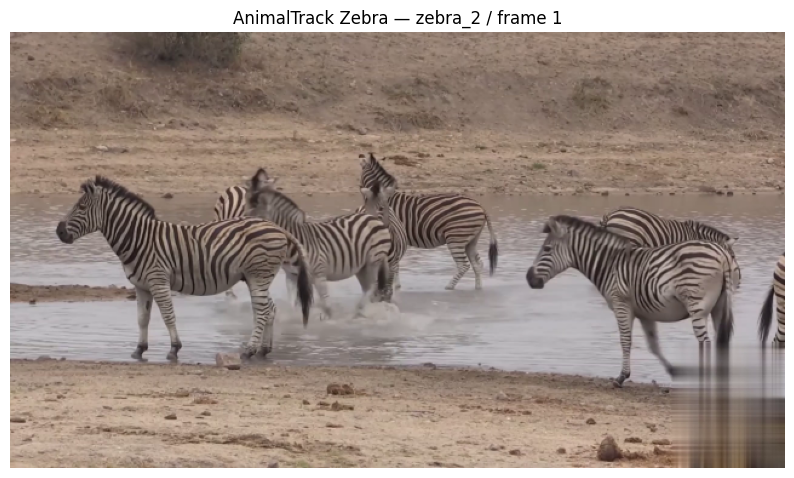

In [5]:
class SequenceReader:
    def __init__(self, sequence):
        self.sequence = sequence
        self.cap = None
        self.frame_map = sequence["frame_map"]
        if sequence["source_type"] == "video":
            self.cap = cv2.VideoCapture(str(sequence["source"]))
            if not self.cap.isOpened():
                raise RuntimeError("Cannot decode video: " + str(sequence["source"]))

    def read(self, i):
        if self.frame_map is not None:
            frame_id, path = self.frame_map[i]
            frame = cv2.imread(str(path))
        else:
            frame_id = i + 1
            self.cap.set(cv2.CAP_PROP_POS_FRAMES, i)
            ok, frame = self.cap.read()
            if not ok:
                frame = None
        if frame is None:
            raise RuntimeError(f"Failed to decode frame index {i}")
        original_h, original_w = frame.shape[:2]
        if original_w > MAX_FRAME_WIDTH:
            new_w = MAX_FRAME_WIDTH
            new_h = max(2, round(original_h * new_w / original_w))
            frame = cv2.resize(frame, (new_w, new_h), interpolation=cv2.INTER_AREA)
        sx = frame.shape[1] / original_w
        sy = frame.shape[0] / original_h
        return int(frame_id), frame, sx, sy

    def close(self):
        if self.cap is not None:
            self.cap.release()


def xywh_to_xyxy(box):
    x, y, w, h = map(float, box)
    return np.array([x, y, x + w, y + h], dtype=np.float64)


def xyxy_to_xywh(box):
    x1, y1, x2, y2 = map(float, box)
    return np.array([x1, y1, max(1., x2 - x1), max(1., y2 - y1)], dtype=np.float64)


def scale_gt(gt_rows, sx, sy):
    out = []
    for row in gt_rows.itertuples(index=False):
        out.append({"id": int(row.id), "box": np.array(
            [row.x * sx, row.y * sy, row.w * sx, row.h * sy], dtype=np.float64)})
    return out


def overlap(a, b):
    ax, ay, aw, ah = np.asarray(a, dtype=float)
    bx, by, bw, bh = np.asarray(b, dtype=float)
    ix = max(0., min(ax + aw, bx + bw) - max(ax, bx))
    iy = max(0., min(ay + ah, by + bh) - max(ay, by))
    intersection = ix * iy
    union = aw * ah + bw * bh - intersection
    return float(intersection / union) if union > 0 else 0.0


def center(box):
    x, y, w, h = np.asarray(box, dtype=float)
    return np.array([x + w / 2, y + h / 2])


def clamp_box(box, width, height):
    x, y, w, h = map(float, box)
    w = min(max(2., w), float(width))
    h = min(max(2., h), float(height))
    x = float(np.clip(x, 0, width - w))
    y = float(np.clip(y, 0, height - h))
    return np.array([x, y, w, h], dtype=float)

START_INDEX = int(np.clip(START_FRAME_OFFSET, 0, max(0, SELECTED["n_frames"] - 1)))
N_PROCESS = min(int(np.ceil(TARGET_DURATION_SECONDS * SELECTED["fps"])),
                SELECTED["n_frames"] - START_INDEX)
if N_PROCESS / SELECTED["fps"] < MIN_DURATION_SECONDS:
    raise RuntimeError("The chosen interval is shorter than the minimum duration.")

reader = SequenceReader(SELECTED)
first_id, first_frame, SX, SY = reader.read(START_INDEX)
reader.close()
print("Processed interval:", N_PROCESS, "frames /", SELECTED["fps"], "FPS =",
      round(N_PROCESS / SELECTED["fps"], 2), "s")
print("Output image resolution:", first_frame.shape[1], "x", first_frame.shape[0])
print("First source frame ID:", first_id, "| Spatial scales:", (round(SX, 4), round(SY, 4)))
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"AnimalTrack Zebra — {SELECTED['name']} / frame {first_id}")
plt.show()

## 7. Zebra detection with YOLO

A pretrained YOLO detector is restricted to the **zebra** category. The class index is resolved from the model's class-name table. Each frame returns detector boxes as $(x,y,w,h)$ in processed image coordinates and a confidence score.

Bounding boxes from YOLO initialize candidate tracks and provide position/scale measurements during EKF correction. Ground-truth boxes are not passed to the detector, the association stage, or the state estimator.


In [6]:
from ultralytics import YOLO

detector = YOLO(YOLO_MODEL)
class_map = detector.names
ZEBRA_CLASS = next((int(index) for index, name in class_map.items()
                    if str(name).strip().lower() == "zebra"), None)
if ZEBRA_CLASS is None:
    raise RuntimeError("The selected YOLO checkpoint does not contain the zebra class")
print("Model:", YOLO_MODEL, "| Zebra class:", ZEBRA_CLASS, "| Device:", DEVICE)


def detect_zebras(frame):
    prediction = detector.predict(
        source=frame, classes=[ZEBRA_CLASS], conf=YOLO_CONFIDENCE,
        imgsz=640, device=DEVICE, verbose=False, max_det=MAX_DETECTIONS,
    )[0]
    boxes = []
    if prediction.boxes is not None:
        xyxy = prediction.boxes.xyxy.cpu().numpy()
        scores = prediction.boxes.conf.cpu().numpy()
        for corners, confidence in zip(xyxy, scores):
            box = xyxy_to_xywh(corners)
            if box[2] > 4 and box[3] > 4:
                boxes.append({"box": box, "confidence": float(confidence)})
    return boxes

example_detections = detect_zebras(first_frame)
print("Zebra detections on first frame:", len(example_detections))
if len(example_detections) == 0:
    print("No zebra detected in the first frame. Lower YOLO_CONFIDENCE or choose a different sequence.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model: yolo11n.pt | Zebra class: 22 | Device: cpu
Zebra detections on first frame: 8


## Initial-frame detection and annotation overlay

The first-frame visualization displays independently generated YOLO boxes together with aligned reference boxes when available. This checks coordinate scaling and allows qualitative inspection of missed detections or localization offsets. The overlay does not initialize or modify tracking states. A reference identity can be selected later for post-hoc trajectory diagnostics.


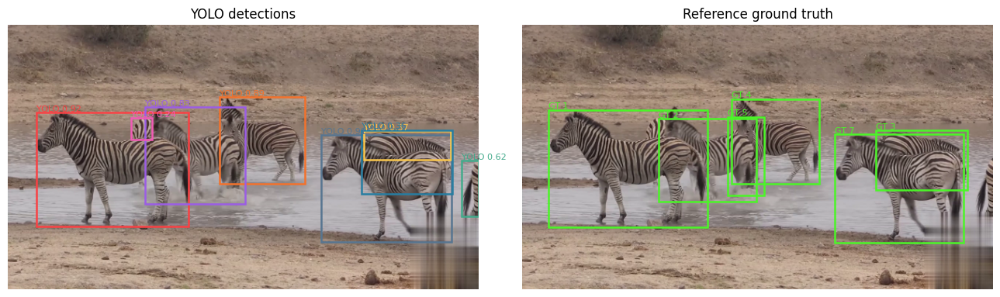

Initial frame: 1 | YOLO detections: 8 | GT boxes: 6


In [7]:
from matplotlib.patches import Rectangle

first_gt_rows = SELECTED["annotations"].loc[
    SELECTED["annotations"].frame == first_id]
first_gt = scale_gt(first_gt_rows, SX, SY)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax in axes:
    ax.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
    ax.axis("off")
for det_idx, det in enumerate(example_detections, 1):
    x, y, w, h = det["box"]
    axes[0].add_patch(Rectangle((x, y), w, h, fill=False, ec=np.array(bgr_to_rgb(color_for_id(det_idx)))/255, lw=1.8))
    axes[0].text(x, max(8, y-2), f"YOLO {det['confidence']:.2f}", color=np.array(bgr_to_rgb(color_for_id(det_idx)))/255, fontsize=8)
for gt in first_gt:
    x, y, w, h = gt["box"]
    axes[1].add_patch(Rectangle((x, y), w, h, fill=False, ec=np.array(VIS_COLORS_RGB["ground_truth"])/255, lw=1.8))
    axes[1].text(x, max(8, y-2), f"GT {gt['id']}", color=np.array(VIS_COLORS_RGB["ground_truth"])/255, fontsize=8)
axes[0].set_title("YOLO detections")
axes[1].set_title("Reference ground truth" if HAS_GT else "Ground truth unavailable")
fig.tight_layout()
fig.savefig(RESULTS / "initial_detection_vs_gt.png", dpi=150)
plt.show()
print("Initial frame:", first_id, "| YOLO detections:", len(example_detections),
      "| GT boxes:", len(first_gt))


## 8. Robust dense Farnebäck observations

Dense flow $\mathbf u_t$ is estimated from two consecutive grayscale images. A contracted region inside the predicted bounding box reduces, but cannot eliminate, background motion contamination. The robust displacement is computed from componentwise inlier medians. A MAD-based estimate of dispersion uses $1.4826\operatorname{median}|u-\operatorname{median}(u)|$ and informs the measurement uncertainty.

Only flow observations that satisfy the implemented validity checks are provided to the EKF; invalid observations are omitted rather than replaced with a fabricated displacement.


In [8]:
def dense_flow(previous_gray, current_gray):
    return cv2.calcOpticalFlowFarneback(
        previous_gray, current_gray, None,
        pyr_scale=0.5, levels=3, winsize=19,
        iterations=3, poly_n=5, poly_sigma=1.2, flags=0
    )


def roi_flow_observation(flow_field, bbox):
    if flow_field is None:
        return None
    height, width = flow_field.shape[:2]
    x, y, w, h = map(float, bbox)
    x1, y1 = int(np.clip(x + w * 0.15, 0, width - 1)), int(np.clip(y + h * 0.15, 0, height - 1))
    x2, y2 = int(np.clip(x + w * 0.85, 0, width)), int(np.clip(y + h * 0.85, 0, height))
    if x2 - x1 < 5 or y2 - y1 < 5:
        return None
    samples = flow_field[y1:y2:2, x1:x2:2].reshape(-1, 2).astype(np.float64)
    samples = samples[np.isfinite(samples).all(axis=1)]
    if len(samples) < 12:
        return None
    med = np.median(samples, axis=0)
    scale = 1.4826 * np.median(np.abs(samples - med), axis=0) + 1e-3
    inliers = np.all(np.abs(samples - med) <= np.maximum(2., 3.0 * scale), axis=1)
    fraction = float(np.mean(inliers))
    if np.count_nonzero(inliers) < 10 or fraction < 0.35:
        return None
    cleaned = samples[inliers]
    delta = np.median(cleaned, axis=0)
    dispersion = float(np.median(np.linalg.norm(cleaned - delta, axis=1)))
    if not np.isfinite(delta).all() or np.linalg.norm(delta) > 90:
        return None
    return delta, dispersion, fraction

## Sparse-flow diagnostics: Shi–Tomasi and pyramidal Lucas–Kanade

The primary tracker uses dense Farnebäck optical flow. A separate sparse-flow diagnostic samples Shi–Tomasi corners within a contracted region and follows them with pyramidal Lucas–Kanade (LK). A point is accepted when its forward–backward reconstruction residual is below $1.5$ pixels; displacement outliers are suppressed with MAD filtering. Sparse LK results are logged and visualized but are not used as EKF measurements.

For an intensity window $W$, the local LK least-squares displacement is

$$\begin{bmatrix}u\\v\end{bmatrix}=\left[\sum_{W}\begin{pmatrix}I_x^2&I_xI_y\\I_xI_y&I_y^2\end{pmatrix}\right]^{-1}\left[-\sum_{W}\begin{pmatrix}I_xI_t\\I_yI_t\end{pmatrix}\right].$$

A short temporal diagnostic tracks accepted features over successive frames and replenishes them from Shi–Tomasi detections when the active count falls below its threshold. The resulting feature counts and refill events describe local tracking stability independently from the dense-flow fusion path.


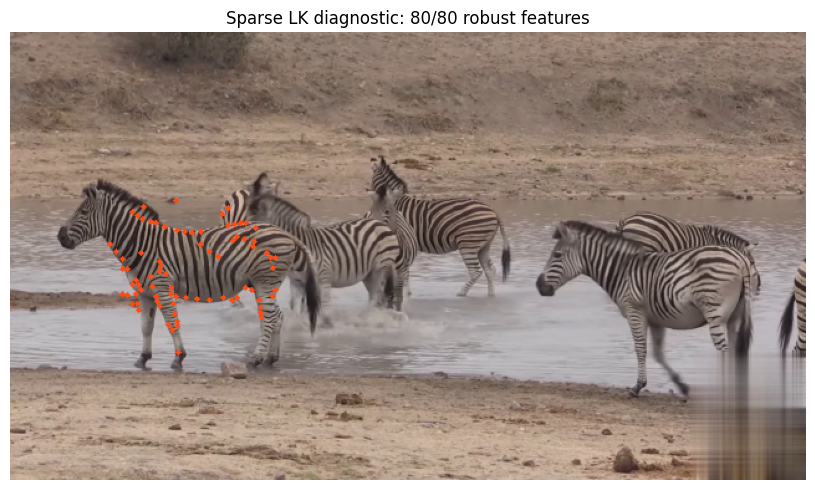

Sparse LK displacement (px/frame): [  -0.020157    -0.17281]
Farnebäck robust ROI displacement (px/frame): [ -0.0086532    -0.13675]


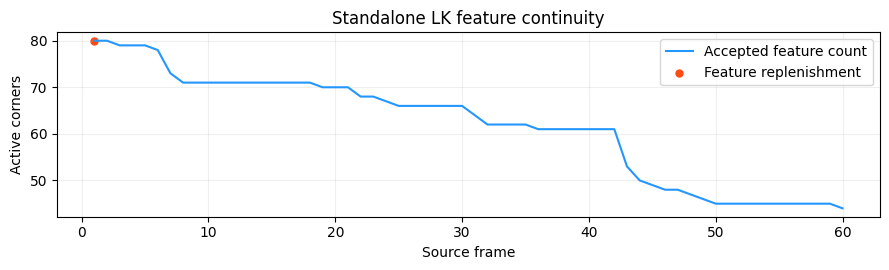

LK diagnostic replenishment events: 1


In [9]:
def sparse_lk_two_frame_diagnostic(previous_bgr, current_bgr, bbox,
                                   fb_threshold=1.5, max_corners=80):
    old_gray = cv2.cvtColor(previous_bgr, cv2.COLOR_BGR2GRAY)
    new_gray = cv2.cvtColor(current_bgr, cv2.COLOR_BGR2GRAY)
    h, w = old_gray.shape[:2]
    x, y, bw, bh = map(float, bbox)
    x1 = int(np.clip(x, 0, w-1)); y1 = int(np.clip(y, 0, h-1))
    x2 = int(np.clip(x+bw, x1+1, w)); y2 = int(np.clip(y+bh, y1+1, h))
    mask = np.zeros_like(old_gray, dtype=np.uint8)
    midpoint = ((x1+x2)//2, (y1+y2)//2)
    axes = (max(2, int((x2-x1)*0.36)), max(2, int((y2-y1)*0.40)))
    cv2.ellipse(mask, midpoint, axes, 0, 0, 360, 255, -1)
    points = cv2.goodFeaturesToTrack(old_gray, maxCorners=max_corners, qualityLevel=0.01,
                                      minDistance=4, blockSize=5, mask=mask)
    if points is None or len(points) < 4:
        return {"initial": 0 if points is None else len(points), "accepted": 0,
                "dx_dy": None, "old": np.empty((0,2)), "new": np.empty((0,2))}
    lk_args = dict(winSize=(21,21), maxLevel=3,
                   criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
    forward, fwd_ok, _ = cv2.calcOpticalFlowPyrLK(old_gray, new_gray, points, None, **lk_args)
    if forward is None or fwd_ok is None:
        return {"initial":len(points), "accepted":0, "dx_dy":None,
                "old":np.empty((0,2)), "new":np.empty((0,2))}
    backward, bwd_ok, _ = cv2.calcOpticalFlowPyrLK(new_gray, old_gray, forward, None, **lk_args)
    if backward is None or bwd_ok is None:
        return {"initial":len(points), "accepted":0, "dx_dy":None,
                "old":np.empty((0,2)), "new":np.empty((0,2))}
    fb = np.linalg.norm(points.reshape(-1,2)-backward.reshape(-1,2), axis=1)
    good = ((fwd_ok.reshape(-1)==1) & (bwd_ok.reshape(-1)==1)
            & np.isfinite(fb) & (fb<fb_threshold))
    old = points.reshape(-1,2)[good]
    new = forward.reshape(-1,2)[good]
    if len(new) < 4:
        return {"initial":len(points), "accepted":len(new), "dx_dy":None,
                "old":old, "new":new}
    drift = new-old
    med = np.median(drift, axis=0)
    radial = np.linalg.norm(drift-med, axis=1)
    mad = np.median(np.abs(radial-np.median(radial)))+1e-6
    reliable = radial <= max(2., np.median(radial)+3.*1.4826*mad)
    if reliable.sum() >= 4:
        old, new = old[reliable], new[reliable]
    delta = np.median(new-old, axis=0)
    return {"initial":len(points), "accepted":len(new), "dx_dy":delta,
            "old":old, "new":new}

lk_diagnostic = None
if N_PROCESS > 1 and example_detections:
    diagnostic_reader = SequenceReader(SELECTED)
    try:
        _, diagnostic_frame2, _, _ = diagnostic_reader.read(START_INDEX+1)
    finally:
        diagnostic_reader.close()
    lk_box = example_detections[0]["box"]
    lk_diagnostic = sparse_lk_two_frame_diagnostic(first_frame, diagnostic_frame2, lk_box)
    flow_sample = dense_flow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2GRAY),
                             cv2.cvtColor(diagnostic_frame2, cv2.COLOR_BGR2GRAY))
    fb_observation = roi_flow_observation(flow_sample, lk_box)
    canvas = cv2.cvtColor(diagnostic_frame2.copy(), cv2.COLOR_BGR2RGB)
    for before, after in zip(lk_diagnostic["old"], lk_diagnostic["new"]):
        a = tuple(np.rint(before).astype(int)); b = tuple(np.rint(after).astype(int))
        cv2.line(canvas, a, b, VIS_COLORS_RGB["lk_motion"], 1, cv2.LINE_AA)
        cv2.circle(canvas, b, 2, VIS_COLORS_RGB["lk_features"], -1)
    fig, ax = plt.subplots(figsize=(11,5))
    ax.imshow(canvas); ax.axis("off")
    ax.set_title(f"Sparse LK diagnostic: {lk_diagnostic['accepted']}/{lk_diagnostic['initial']} robust features")
    fig.tight_layout(); fig.savefig(RESULTS/"sparse_lk_diagnostic.png", dpi=160); plt.show()
    print("Sparse LK displacement (px/frame):", lk_diagnostic["dx_dy"])
    print("Farnebäck robust ROI displacement (px/frame):",
          None if fb_observation is None else fb_observation[0])
else:
    print("Sparse-flow diagnostic skipped: no initial YOLO zebra or insufficient frames.")

# Replenish sparse LK features independently of the dense-flow EKF.
def lk_refresh_sequence_diagnostic(sequence, first_box, start_index, sample_frames=60,
                                   min_features=5, refresh_threshold=14):
    reader = SequenceReader(sequence)
    mask_frame = None
    points = None
    box = np.asarray(first_box, dtype=np.float64).copy()
    output=[]
    def corners(gray, roi_box):
        height, width=gray.shape[:2]
        x,y,w,h=map(float,roi_box)
        mask=np.zeros((height,width),np.uint8)
        center_xy=(int(np.clip(x+w/2,0,width-1)),int(np.clip(y+h/2,0,height-1)))
        axes=(max(2,int(w*.36)),max(2,int(h*.40)))
        cv2.ellipse(mask,center_xy,axes,0,0,360,255,-1)
        return cv2.goodFeaturesToTrack(gray,maxCorners=80,qualityLevel=.01,
                                       minDistance=4,blockSize=5,mask=mask)
    lk_kwargs=dict(winSize=(21,21),maxLevel=3,
                   criteria=(cv2.TERM_CRITERIA_EPS|cv2.TERM_CRITERIA_COUNT,30,.01))
    try:
        last=min(sequence["n_frames"],start_index+sample_frames)
        for i in range(start_index,last):
            fid, frame, _, _=reader.read(i)
            gray=cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
            shift=np.array([np.nan,np.nan],dtype=float)
            refreshed=False
            if mask_frame is not None and points is not None and len(points)>=min_features:
                nxt, status, _=cv2.calcOpticalFlowPyrLK(mask_frame,gray,points,None,**lk_kwargs)
                if nxt is not None and status is not None:
                    backward, back_status, _=cv2.calcOpticalFlowPyrLK(gray,mask_frame,nxt,None,**lk_kwargs)
                    if backward is not None and back_status is not None:
                        fb=np.linalg.norm(points.reshape(-1,2)-backward.reshape(-1,2),axis=1)
                        valid=(status.reshape(-1)==1)&(back_status.reshape(-1)==1)&(fb<1.5)&np.isfinite(fb)
                        old=points.reshape(-1,2)[valid]; new=nxt.reshape(-1,2)[valid]
                        if len(new)>=min_features:
                            displacement=new-old
                            median=np.median(displacement,axis=0)
                            errors=np.linalg.norm(displacement-median,axis=1)
                            mad=np.median(np.abs(errors-np.median(errors)))+1e-6
                            keep=errors<=max(2.,np.median(errors)+3*1.4826*mad)
                            if keep.sum()>=min_features:
                                new=new[keep]; displacement=displacement[keep]
                            shift=np.median(displacement,axis=0)
                            box[0:2]+=shift
                            box=clamp_box(box,gray.shape[1],gray.shape[0])
                            points=new.reshape(-1,1,2).astype(np.float32)
                        else:
                            points=None
                    else:
                        points=None
                else:
                    points=None
            if points is None or len(points)<refresh_threshold:
                fresh=corners(gray,box)
                if fresh is not None and len(fresh)>=min_features:
                    points=fresh
                    refreshed=True
                elif points is None:
                    points=np.empty((0,1,2),dtype=np.float32)
            mask_frame=gray.copy()
            output.append({"frame":fid,"feature_count":len(points),"refreshed":refreshed,
                           "dx":float(shift[0]),"dy":float(shift[1]),
                           "box_cx":float(center(box)[0]),"box_cy":float(center(box)[1])})
    finally:
        reader.close()
    return pd.DataFrame(output)

if example_detections and N_PROCESS>1:
    lk_history=lk_refresh_sequence_diagnostic(SELECTED,example_detections[0]["box"],
                                               START_INDEX,min(N_PROCESS,60))
    lk_history.to_csv(RESULTS/"sparse_lk_feature_diagnostics.csv",index=False)
    fig,ax=plt.subplots(figsize=(9,2.8))
    ax.plot(lk_history.frame,lk_history.feature_count,label="Accepted feature count",
            color=np.array(VIS_COLORS_RGB["lk_motion"])/255)
    refreshed=lk_history[lk_history.refreshed]
    if not refreshed.empty:
        ax.scatter(refreshed.frame,refreshed.feature_count,color=np.array(VIS_COLORS_RGB["lk_features"])/255,s=25,
                   label="Feature replenishment")
    ax.set(xlabel="Source frame",ylabel="Active corners",title="Standalone LK feature continuity")
    ax.grid(alpha=.2);ax.legend(loc="best");fig.tight_layout()
    fig.savefig(RESULTS/"sparse_lk_feature_refresh.png",dpi=150);plt.show()
    print("LK diagnostic replenishment events:",int(lk_history.refreshed.sum()))


## 9. CTRV extended Kalman filter

A finite-difference Jacobian locally linearizes the nonlinear CTRV transition around the predicted state. Measurement updates combine available detection and flow observations according to their specified observation models and noise covariances.

The covariance is updated in Joseph form,

$$\mathbf P\leftarrow(\mathbf I-\mathbf K\mathbf H)\mathbf P(\mathbf I-\mathbf K\mathbf H)^\mathsf T+\mathbf K\mathbf R\mathbf K^\mathsf T,$$

which reduces numerical asymmetry and loss of positive semidefiniteness under finite-precision arithmetic.


In [10]:
def wrap_angle(value):
    return (value + np.pi) % (2.0 * np.pi) - np.pi


def ctrv_transition(state, dt):
    s = np.asarray(state, dtype=np.float64).copy()
    x, y, speed, heading, turn_rate, log_w, log_h = s
    if abs(turn_rate) > 1e-4:
        next_heading = heading + turn_rate * dt
        s[0] = x + speed / turn_rate * (np.sin(next_heading) - np.sin(heading))
        s[1] = y + speed / turn_rate * (np.cos(heading) - np.cos(next_heading))
    else:
        s[0] = x + speed * dt * np.cos(heading)
        s[1] = y + speed * dt * np.sin(heading)
    s[3] = wrap_angle(heading + turn_rate * dt)
    return s


def transition_jacobian(state, dt):
    size = len(state)
    matrix = np.zeros((size, size), dtype=np.float64)
    step = 1e-5
    for j in range(size):
        plus, minus = state.copy(), state.copy()
        plus[j] += step
        minus[j] -= step
        diff = ctrv_transition(plus, dt) - ctrv_transition(minus, dt)
        if j == 3:
            diff[3] = wrap_angle(diff[3])
        matrix[:, j] = diff / (2 * step)
    return matrix


class ZebraEKF:
    def __init__(self, box):
        x, y, w, h = np.asarray(box, dtype=float)
        self.state = np.array([x + w / 2, y + h / 2, 0., 0., 0.,
                               np.log(max(w, 2.)), np.log(max(h, 2.))])
        self.P = np.diag([70., 70., 1200., 1., 0.7, 0.15, 0.15])
        self.Hd = np.zeros((4, 7))
        self.Hd[0, 0] = self.Hd[1, 1] = 1.
        self.Hd[2, 5] = self.Hd[3, 6] = 1.
        self.Hf = np.zeros((2, 7))
        self.Hf[0, 0] = self.Hf[1, 1] = 1.

    def box(self):
        cx, cy = self.state[:2]
        w, h = np.exp(np.clip(self.state[5:7], np.log(2.), np.log(3000.)))
        return np.array([cx - w / 2., cy - h / 2., w, h], dtype=float)

    def predict(self, dt):
        F = transition_jacobian(self.state, dt)
        self.state = ctrv_transition(self.state, dt)
        Q = np.diag([2.5, 2.5, 140., 0.03, 0.03, 0.005, 0.005])
        self.P = F @ self.P @ F.T + Q

    def _update(self, z, H, R):
        residual = np.asarray(z) - H @ self.state
        S = H @ self.P @ H.T + R
        K = np.linalg.solve(S, H @ self.P).T
        self.state += K @ residual
        self.state[3] = wrap_angle(self.state[3])
        I_KH = np.eye(7) - K @ H
        self.P = I_KH @ self.P @ I_KH.T + K @ R @ K.T
        self.P = (self.P + self.P.T) / 2.

    def update_detection(self, box):
        x, y, w, h = map(float, box)
        z = np.array([x + w / 2., y + h / 2., np.log(max(w, 2.)), np.log(max(h, 2.))])
        self._update(z, self.Hd, np.diag([36., 36., 0.09, 0.09]))

    def update_flow(self, center_xy, dispersion):
        sigma = float(np.clip(7. + 1.5 * dispersion, 7., 40.))
        self._update(np.asarray(center_xy), self.Hf, np.diag([sigma * sigma, sigma * sigma]))


# Validate deterministic state and covariance algebra numerically.
assert np.allclose(ctrv_transition(np.array([2., 3., 6., 0., 0., 2., 2.]), 1.)[:2], [8., 3.])
assert abs(overlap([0, 0, 10, 10], [0, 0, 10, 10]) - 1.) < 1e-9
assert np.isfinite(transition_jacobian(np.array([0., 0., 2., 0.1, 0.05, 2., 2.]), .04)).all()

def position_covariance_ellipse(position_covariance, n_std=2.0):
    cov = np.asarray(position_covariance, dtype=float).reshape(2,2)
    cov = 0.5*(cov+cov.T)
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = np.maximum(eigenvalues[order], 1e-8)
    major_direction = eigenvectors[:, order[0]]
    degrees = float(np.degrees(np.arctan2(major_direction[1], major_direction[0])))
    return (degrees, float(n_std*np.sqrt(eigenvalues[0])),
            float(n_std*np.sqrt(eigenvalues[1])))

probe = ZebraEKF([20., 20., 60., 35.])
prior_c = probe.state[:2].copy()
probe.predict(1./SELECTED["fps"])
print("Example EKF center (prior -> prediction):", np.round(prior_c,2),
      "->", np.round(probe.state[:2],2))
print("Example 2-sigma position ellipse:",
      tuple(round(x,3) for x in position_covariance_ellipse(probe.P[:2,:2])))

# Linear constant-velocity matrices for state-space comparison only.
dt_ref=1.0/SELECTED["fps"]
F_cv=np.array([[1,0,dt_ref,0],[0,1,0,dt_ref],[0,0,1,0],[0,0,0,1]],dtype=float)
G_cv=np.array([[0.5*dt_ref**2,0],[0,0.5*dt_ref**2],[dt_ref,0],[0,dt_ref]],dtype=float)
Q_cv=25.0*(G_cv@G_cv.T)
R_cv=np.eye(2)*16.0
print("Linear CV reference F/Q/R shapes:",F_cv.shape,Q_cv.shape,R_cv.shape)
print("CTRV-EKF transition Jacobian shape:",transition_jacobian(probe.state,dt_ref).shape)

Example EKF center (prior -> prediction): [         50        37.5] -> [         50        37.5]
Example 2-sigma position ellipse: (0.0, 17.185, 17.029)
Linear CV reference F/Q/R shapes: (4, 4) (4, 4) (2, 2)
CTRV-EKF transition Jacobian shape: (7, 7)


## EKF prediction, correction, and uncertainty

For the nonlinear transition, $\mathbf F_t=\partial\mathbf f/\partial\mathbf x$ propagates state covariance. Predicted location, accepted flow observation, detector measurement, and corrected location are recorded separately. In the absence of YOLO detections, a valid flow measurement can still update the state; if neither observation is usable, the filter propagates its prediction alone.

A $2\sigma$ ellipse is drawn using the eigenvectors and eigenvalues of the position covariance submatrix $\mathbf P_{xy}=\mathbf P_{0:2,0:2}$. This ellipse visualizes the filter's estimated spatial uncertainty and does not establish empirical coverage or probabilistic calibration.


## 10. Track lifecycle and multi-object association

A track stores a persistent numerical identity, age, detection-hit count, missed-frame count, bounding box, and recent center history. The fusion branch predicts CTRV state, applies a valid dense-flow update when present, and corrects the matched track with YOLO. Unmatched tracks are maintained for a limited interval and then removed.

The baseline performs geometric detection association without the dense-flow EKF fusion. Both branches consume the same detector outputs and use the same input frame stream, allowing the contribution of the motion model to be examined without detector-input differences.


In [11]:
class Track:
    def __init__(self, number, box, mode):
        self.id = int(number)
        self.mode = mode
        self.filter = ZebraEKF(box) if mode == "fusion" else None
        self.last_box = np.asarray(box, dtype=float).copy()
        self.hits = 1
        self.misses = 0
        self.flow_updates = 0
        self.trace = [center(box).tolist()]
        self.prior_center = center(box).copy()
        self.flow_center = np.array([np.nan, np.nan])
        self.detection_center = center(box).copy()
        self.flow_accepted = False

    @property
    def box(self):
        return self.filter.box() if self.mode == "fusion" else self.last_box.copy()

    def predict(self, dt, flow):
        previous = self.box
        previous_center = center(previous)
        self.flow_center = np.array([np.nan, np.nan])
        self.detection_center = np.array([np.nan, np.nan])
        self.flow_accepted = False
        if self.filter is not None:
            self.filter.predict(dt)
            self.prior_center = self.filter.state[:2].copy()
            observed = roi_flow_observation(flow, previous)
            if observed is not None:
                displacement, dispersion, fraction = observed
                self.flow_center = previous_center + displacement
                self.filter.update_flow(self.flow_center, dispersion)
                self.flow_updates += 1
                self.flow_accepted = True
        if self.filter is None:
            self.prior_center = previous_center.copy()
        self.misses += 1
        self.trace.append(center(self.box).tolist())
        self.trace = self.trace[-120:]

    def correct(self, measurement):
        self.detection_center = center(measurement).copy()
        if self.filter is not None:
            self.filter.update_detection(measurement)
        else:
            self.last_box = np.asarray(measurement, dtype=float).copy()
        self.hits += 1
        self.misses = 0
        self.trace[-1] = center(self.box).tolist()


class Tracker:
    def __init__(self, mode, max_misses=MAX_MISSED_FRAMES):
        self.mode = mode
        self.active = []
        self.next_id = 1
        self.max_misses = max_misses
        self.total_flow_updates = 0

    def step(self, detections, flow, dt, image_shape):
        height, width = image_shape[:2]
        for track in self.active:
            track.predict(dt, flow if self.mode == "fusion" else None)
        n, m = len(self.active), len(detections)
        assigned_tracks, assigned_detections = set(), set()
        if n and m:
            costs = np.full((n, m), 1e5, dtype=float)
            for i, track in enumerate(self.active):
                reference = clamp_box(track.box, width, height)
                diagonal = max(12., np.hypot(reference[2], reference[3]))
                for j, detection in enumerate(detections):
                    proposal = detection["box"]
                    iou = overlap(reference, proposal)
                    distance = float(np.linalg.norm(center(reference) - center(proposal)))
                    if iou >= 0.04 or distance <= 0.85 * diagonal:
                        costs[i, j] = 0.60 * (1. - iou) + 0.40 * min(distance / diagonal, 1.)
            rows, cols = linear_sum_assignment(costs)
            for i, j in zip(rows.tolist(), cols.tolist()):
                if costs[i, j] >= 0.95:
                    continue
                self.active[i].correct(detections[j]["box"])
                assigned_tracks.add(i)
                assigned_detections.add(j)
        for j, detection in enumerate(detections):
            if j not in assigned_detections:
                self.active.append(Track(self.next_id, detection["box"], self.mode))
                self.next_id += 1
        self.active = [track for track in self.active if track.misses <= self.max_misses]
        self.total_flow_updates = sum(t.flow_updates for t in self.active)
        result = []
        for track in self.active:
            if track.hits < 2 and track.misses > 0:
                continue
            entry = {"id": track.id, "box": clamp_box(track.box,width,height),
                     "misses":track.misses,"trace":track.trace.copy(),"hits":track.hits,
                     "prior_cx":float(track.prior_center[0]),
                     "prior_cy":float(track.prior_center[1]),
                     "flow_cx":float(track.flow_center[0]),
                     "flow_cy":float(track.flow_center[1]),
                     "detection_cx":float(track.detection_center[0]),
                     "detection_cy":float(track.detection_center[1]),
                     "flow_accepted":bool(track.flow_accepted)}
            if track.filter is not None:
                state=track.filter.state
                angle, major, minor = position_covariance_ellipse(track.filter.P[:2,:2])
                entry.update({"posterior_cx":float(state[0]),"posterior_cy":float(state[1]),
                    "speed_px_s":float(state[2]),"heading_deg":float(np.degrees(state[3])),
                    "turn_rate_deg_s":float(np.degrees(state[4])),
                    "sigma_major_px":major,"sigma_minor_px":minor,"ellipse_angle_deg":angle})
            else:
                xy=center(track.box)
                entry.update({"posterior_cx":float(xy[0]),"posterior_cy":float(xy[1]),
                    "speed_px_s":np.nan,"heading_deg":np.nan,
                    "turn_rate_deg_s":np.nan,"sigma_major_px":np.nan,
                    "sigma_minor_px":np.nan,"ellipse_angle_deg":np.nan})
            result.append(entry)
        return result

## 11. Reference matching and identity statistics

Frame-level evaluation is performed after tracking using a separate Hungarian assignment at $\operatorname{IoU}\geq0.5$. Its associations determine true positives, false positives, unmatched ground-truth objects, matched localization error, and changes of assigned predicted identities.

An additional sequence-level assignment over reference/predicted ID co-occurrences gives a **global IDF1 proxy**. Because this is not the official IDF1 implementation, the reported value must not be compared directly with TrackEval benchmark scores.


In [12]:
def match_frame(preds, ground_truth, iou_threshold=MATCH_IOU_THRESHOLD):
    if not preds or not ground_truth:
        return []
    score = np.array([[overlap(t["box"], g["box"]) for g in ground_truth]
                      for t in preds], dtype=float)
    rr, cc = linear_sum_assignment(1.0 - score)
    return [(int(i), int(j), float(score[i, j])) for i, j in zip(rr, cc)
            if score[i, j] >= iou_threshold]


class Evaluator:
    def __init__(self, label):
        self.label = label
        self.tp = self.fp = self.fn = self.ids = self.gt_total = self.pred_total = 0
        self.iou_values = []
        self.center_errors = []
        self.pair_counts = Counter()
        self.prev_assignment = {}
        self.frames = []

    def update(self, frame_id, preds, ground_truth):
        if not HAS_GT:
            stats = {"frame": frame_id, "method": self.label, "gt": np.nan,
                     "predictions": len(preds), "TP": np.nan, "FP": np.nan,
                     "FN": np.nan, "ID_switches": np.nan,
                     "mean_CLE_px_matched": np.nan,
                     "mean_IoU_matched": np.nan}
            self.frames.append(stats)
            self.pred_total += len(preds)
            return stats
        pairs = match_frame(preds, ground_truth)
        tp = len(pairs)
        fp = len(preds) - tp
        fn = len(ground_truth) - tp
        self.tp += tp
        self.fp += fp
        self.fn += fn
        self.gt_total += len(ground_truth)
        self.pred_total += len(preds)
        frame_errors = []
        switches = 0
        for pi, gi, iou in pairs:
            pred, gt = preds[pi], ground_truth[gi]
            err = float(np.linalg.norm(center(pred["box"]) - center(gt["box"])))
            self.center_errors.append(err)
            self.iou_values.append(iou)
            frame_errors.append(err)
            gt_id, pred_id = int(gt["id"]), int(pred["id"])
            if gt_id in self.prev_assignment and self.prev_assignment[gt_id] != pred_id:
                switches += 1
            self.prev_assignment[gt_id] = pred_id
            self.pair_counts[(gt_id, pred_id)] += 1
        self.ids += switches
        stats = {"frame": frame_id, "method": self.label, "gt": len(ground_truth),
                 "predictions": len(preds), "TP": tp, "FP": fp, "FN": fn,
                 "ID_switches": switches,
                 "mean_CLE_px_matched": np.mean(frame_errors) if frame_errors else np.nan,
                 "mean_IoU_matched": np.mean([p[2] for p in pairs]) if pairs else np.nan}
        self.frames.append(stats)
        return stats

    def identity_f1_proxy(self):
        gt_ids = sorted({a for a, _ in self.pair_counts})
        pred_ids = sorted({b for _, b in self.pair_counts})
        if not gt_ids or not pred_ids:
            return 0.
        weights = np.zeros((len(gt_ids), len(pred_ids)))
        for (gid, pid), n in self.pair_counts.items():
            weights[gt_ids.index(gid), pred_ids.index(pid)] += n
        rows, cols = linear_sum_assignment(-weights)
        idtp = float(weights[rows, cols].sum())
        return 2 * idtp / max(self.gt_total + self.pred_total, 1)

    def summary(self):
        if not HAS_GT:
            return {"method": self.label, "TP": np.nan, "FP": np.nan,
                    "FN": np.nan, "ID_switches": np.nan,
                    "precision_at_IoU_0.5": np.nan, "recall_at_IoU_0.5": np.nan,
                    "F1_at_IoU_0.5": np.nan, "MOTA": np.nan,
                    "global_IDF1_proxy": np.nan, "mean_IoU_matched": np.nan,
                    "mean_CLE_px_matched": np.nan}
        p = self.tp / max(self.tp + self.fp, 1)
        r = self.tp / max(self.tp + self.fn, 1)
        return {"method": self.label, "TP": self.tp, "FP": self.fp, "FN": self.fn,
                "ID_switches": self.ids, "precision_at_IoU_0.5": p,
                "recall_at_IoU_0.5": r, "F1_at_IoU_0.5": 2*p*r/(p+r) if p+r else 0.,
                "MOTA": 1 - (self.fp + self.fn + self.ids) / max(self.gt_total, 1),
                "global_IDF1_proxy": self.identity_f1_proxy(),
                "mean_IoU_matched": float(np.mean(self.iou_values)) if self.iou_values else np.nan,
                "mean_CLE_px_matched": float(np.mean(self.center_errors)) if self.center_errors else np.nan}

## 12. Tracking overlays and H.264 encoding

Rendered frames contain predicted boxes, persistent IDs, center markers, and recent trajectories. Each identity has a stable box color and a lighter trajectory color; separate colors distinguish YOLO observations, flow displacement, EKF prediction/correction, and covariance ellipses. Dashed boxes indicate states carried forward without an associated detection.

Reference annotations are excluded from inference panels and are rendered only in designated evaluation images. The baseline and fusion panels are written to intermediate MPEG-4 streams, then transcoded with FFmpeg to H.264 using `yuv420p` and fast-start metadata for browser playback.


In [13]:
def _dashed_box(canvas, x1, y1, x2, y2, color, thickness=2, dash=9):
    # Dashed edges indicate a propagated state without a matched detection.
    for a, b, axis in ((x1, x2, 0), (y1, y2, 1)):
        for start in range(a, b, dash * 2):
            stop = min(start + dash, b)
            if axis == 0:
                cv2.line(canvas, (start, y1), (stop, y1), color, thickness, cv2.LINE_AA)
                cv2.line(canvas, (start, y2), (stop, y2), color, thickness, cv2.LINE_AA)
            else:
                cv2.line(canvas, (x1, start), (x1, stop), color, thickness, cv2.LINE_AA)
                cv2.line(canvas, (x2, start), (x2, stop), color, thickness, cv2.LINE_AA)


def _point_on_canvas(canvas, x, y, color, radius=4):
    if np.isfinite(x) and np.isfinite(y):
        p = (int(round(float(x))), int(round(float(y))))
        if 0 <= p[0] < canvas.shape[1] and 0 <= p[1] < canvas.shape[0]:
            cv2.circle(canvas, p, radius, (10, 10, 10), -1, cv2.LINE_AA)
            cv2.circle(canvas, p, radius-1, color, -1, cv2.LINE_AA)


def _draw_overlay_legend(canvas, mode):
    if not DRAW_OUTPUT_LEGEND:
        return
    components = [("ID box", color_for_id(1)),
                  ("Path", trace_color_for_id(1)),
                  ("YOLO", VIS_COLORS_BGR["detection"])]
    if mode == "fusion":
        components += [("Prior", VIS_COLORS_BGR["prediction"]),
                       ("Flow", VIS_COLORS_BGR["flow"]),
                       ("EKF", VIS_COLORS_BGR["posterior"]),
                       ("2s", VIS_COLORS_BGR["uncertainty"])]
    h, w = canvas.shape[:2]
    if h < 90:
        return
    overlay = canvas.copy()
    cv2.rectangle(overlay, (0, h-27), (w, h), VIS_COLORS_BGR["background"], -1)
    cv2.addWeighted(overlay, 0.74, canvas, 0.26, 0, canvas)
    x = 9
    for name, color in components:
        step = 15 + cv2.getTextSize(name, cv2.FONT_HERSHEY_SIMPLEX, 0.34, 1)[0][0] + 10
        if x + step >= w - 4:
            break
        cv2.rectangle(canvas, (x, h-18), (x+8, h-10), color, -1)
        cv2.putText(canvas, name, (x+12, h-10), cv2.FONT_HERSHEY_SIMPLEX,
                    0.34, VIS_COLORS_BGR["text"], 1, cv2.LINE_AA)
        x += step


def draw_tracks(frame, tracks, header, color=None, mode="baseline"):
    # Preserve the callable signature; draw target boxes with identity colors.
    canvas = frame.copy()
    method_color = VIS_COLORS_BGR["fusion" if mode == "fusion" else "baseline"]
    cv2.rectangle(canvas, (0, 0), (canvas.shape[1], 38),
                  VIS_COLORS_BGR["background"], -1)
    cv2.rectangle(canvas, (0, 0), (6, 38), method_color, -1)
    cv2.putText(canvas, header, (14, 26), cv2.FONT_HERSHEY_SIMPLEX,
                0.61, VIS_COLORS_BGR["text"], 2, cv2.LINE_AA)

    for track in tracks:
        box = clamp_box(track["box"], canvas.shape[1], canvas.shape[0])
        x, y, w, h = np.rint(box).astype(int)
        identity_color = color_for_id(track["id"])
        path_color = trace_color_for_id(track["id"])
        missing = int(track.get("misses", 0)) > 0

        if missing:
            _dashed_box(canvas, x, y, x+w, y+h, identity_color, thickness=2)
        else:
            cv2.rectangle(canvas, (x, y), (x+w, y+h), identity_color, 2, cv2.LINE_AA)

        # Keep the identity label color invariant across frames and branches.
        title = f"Zebra {track['id']}" + (" [pred]" if missing else "")
        label_width = cv2.getTextSize(title, cv2.FONT_HERSHEY_SIMPLEX, 0.43, 1)[0][0] + 10
        label_top = max(38, y-20)
        label_left = max(0, min(x, canvas.shape[1]-label_width-1))
        cv2.rectangle(canvas, (label_left, label_top),
                      (label_left+label_width, label_top+19), identity_color, -1)
        cv2.putText(canvas, title, (label_left+5, label_top+13),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.43, (12, 12, 12), 1, cv2.LINE_AA)

        pts = np.array(track.get("trace", []), dtype=np.float32).reshape(-1, 2)
        valid = np.isfinite(pts).all(axis=1)
        pts = pts[valid]
        if len(pts) > 1:
            cv2.polylines(canvas, [np.rint(pts).astype(np.int32)],
                          False, path_color, 2, cv2.LINE_AA)

        if mode == "fusion":
            sigma_major = track.get("sigma_major_px", np.nan)
            sigma_minor = track.get("sigma_minor_px", np.nan)
            if (DRAW_EKF_UNCERTAINTY and np.isfinite(sigma_major)
                    and np.isfinite(sigma_minor)):
                cx, cy = center(box)
                major = int(np.clip(sigma_major, 1, 100))
                minor = int(np.clip(sigma_minor, 1, 100))
                angle = float(track.get("ellipse_angle_deg", 0.0))
                cv2.ellipse(canvas, (int(cx), int(cy)), (major, minor),
                            angle, 0, 360, VIS_COLORS_BGR["uncertainty"], 2, cv2.LINE_AA)
            if DRAW_STATE_MARKERS:
                _point_on_canvas(canvas, track.get("prior_cx", np.nan),
                                 track.get("prior_cy", np.nan), VIS_COLORS_BGR["prediction"])
                if track.get("flow_accepted", False):
                    _point_on_canvas(canvas, track.get("flow_cx", np.nan),
                                     track.get("flow_cy", np.nan), VIS_COLORS_BGR["flow"])
                _point_on_canvas(canvas, track.get("posterior_cx", np.nan),
                                 track.get("posterior_cy", np.nan), VIS_COLORS_BGR["posterior"])

        if DRAW_STATE_MARKERS and not missing:
            _point_on_canvas(canvas, track.get("detection_cx", np.nan),
                             track.get("detection_cy", np.nan), VIS_COLORS_BGR["detection"])

    _draw_overlay_legend(canvas, mode)
    return canvas


def open_writer(path, fps, size):
    writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"),
                             float(fps), tuple(map(int, size)))
    if not writer.isOpened():
        raise RuntimeError("OpenCV could not initialize MP4 writer: " + str(path))
    return writer


def encode_h264(source):
    source = Path(source)
    target = source.with_name(source.stem + "_h264.mp4")
    if shutil.which("ffmpeg") is None:
        raise RuntimeError("ffmpeg executable is required for browser-compatible MP4")
    command = ["ffmpeg", "-y", "-loglevel", "error", "-i", str(source),
               "-c:v", "libx264", "-preset", "veryfast", "-crf", "23",
               "-pix_fmt", "yuv420p", "-movflags", "+faststart",
               "-an", str(target)]
    subprocess.run(command, check=True)
    cap = cv2.VideoCapture(str(target))
    ok, _ = cap.read()
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    if not ok or frame_count <= 0 or target.stat().st_size <= 0:
        raise RuntimeError(f"H.264 output could not be decoded: {target}")
    source.unlink()
    return target

## 13. Sequential inference and execution timing

The video-processing loop decodes each frame once and evaluates YOLO once. Identical cached detections are passed to the baseline and the Farnebäck–EKF branch. Dense flow is estimated between successive frames, and predicted tracks are associated, corrected, scored, and rendered sequentially.

The reported per-frame runtime includes detector inference, dense optical flow, association, EKF operations, and image rendering. H.264 transcoding and interactive notebook display are excluded. Aggregate throughput is obtained from the measured processing interval rather than the source video FPS.


## Detection-dropout sensitivity analysis

An optional zero-based processed-frame interval suppresses YOLO observations in both tracking branches while leaving original frames intact. Dense Farnebäck flow remains available to the EKF branch. This isolates response to missing detector measurements; it is **not** an image-level occlusion simulation.

The default configuration disables dropout. If enabled, its start/end indices and the number of affected frames are written to the run metadata, so the resulting metrics can be interpreted under the correct measurement-availability condition.


In [14]:
SIMULATE_DETECTION_DROPOUT = False  # Disable detector-observation dropout under the default configuration.
DROPOUT_START_INDEX = 40            # Inclusive boundary in zero-based processed-frame coordinates.
DROPOUT_END_INDEX = 55              # Inclusive boundary in zero-based processed-frame coordinates.
DRAW_EKF_UNCERTAINTY = True

if DROPOUT_END_INDEX < DROPOUT_START_INDEX:
    raise ValueError("Dropout end index must be >= start index")
print("Detection-dropout enabled:", SIMULATE_DETECTION_DROPOUT,
      "| relative frames:", (DROPOUT_START_INDEX, DROPOUT_END_INDEX))

Detection-dropout enabled: False | relative frames: (40, 55)


In [15]:
reader = SequenceReader(SELECTED)
gt_grouped = {int(i): group for i, group in SELECTED["annotations"].groupby("frame", sort=False)}
fusion = Tracker("fusion")
baseline = Tracker("baseline")
score_fusion = Evaluator("YOLO+Farneback+EKF")
score_baseline = Evaluator("YOLO+Association")
per_frame_times = []
track_rows = []
frame_ids_processed = []
flow_magnitudes = []
detector_counts = []
dropout_flags = []
previous_gray = None
width, height = first_frame.shape[1], first_frame.shape[0]
base_path = RESULTS / "zebra_yolo_baseline_raw.mp4"
fusion_path = RESULTS / "zebra_ekf_farneback_yolo_raw.mp4"
compare_path = RESULTS / "zebra_comparison_raw.mp4"
base_writer = open_writer(base_path, SELECTED["fps"], (width, height))
fusion_writer = open_writer(fusion_path, SELECTED["fps"], (width, height))
compare_writer = open_writer(compare_path, SELECTED["fps"], (width * 2, height))

try:
    for i in tqdm(range(START_INDEX, START_INDEX + N_PROCESS), desc="Tracking zebra frames"):
        tic = time.perf_counter()
        frame_id, frame, sx, sy = reader.read(i)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        flow = dense_flow(previous_gray, gray) if previous_gray is not None else None
        if flow is not None:
            flow_magnitudes.append(float(np.median(np.linalg.norm(flow[::8, ::8], axis=2))))
        else:
            flow_magnitudes.append(0.0)
        detections = detect_zebras(frame)
        detections = sorted(detections, key=lambda z: z["confidence"], reverse=True)[:MAX_DETECTIONS]
        detector_counts.append(len(detections))
        relative_frame = i - START_INDEX
        dropout = (SIMULATE_DETECTION_DROPOUT and
                   DROPOUT_START_INDEX <= relative_frame <= DROPOUT_END_INDEX)
        dropout_flags.append(bool(dropout))
        if dropout:
            detections = []
        dt = 1. / SELECTED["fps"]
        baseline_tracks = baseline.step(detections, None, dt, frame.shape)
        fusion_tracks = fusion.step(detections, flow, dt, frame.shape)
        ground_truth = scale_gt(gt_grouped.get(frame_id, pd.DataFrame(columns=SELECTED["annotations"].columns)), sx, sy)
        score_baseline.update(frame_id, baseline_tracks, ground_truth)
        score_fusion.update(frame_id, fusion_tracks, ground_truth)
        for t in fusion_tracks:
            x, y, w, h = map(float, t["box"])
            track_rows.append({"frame": frame_id, "track_id": t["id"],
                               "x": x, "y": y, "width": w, "height": h,
                               "predicted_without_detection": bool(t["misses"]),
                               "x_center": x+w/2, "y_center": y+h/2,
                               "prior_cx":t["prior_cx"],"prior_cy":t["prior_cy"],
                               "flow_cx":t["flow_cx"],"flow_cy":t["flow_cy"],
                               "posterior_cx":t["posterior_cx"],
                               "posterior_cy":t["posterior_cy"],
                               "detection_cx":t["detection_cx"],
                               "detection_cy":t["detection_cy"],
                               "flow_accepted":t["flow_accepted"],
                               "speed_px_s":t["speed_px_s"],
                               "heading_deg":t["heading_deg"],
                               "turn_rate_deg_s":t["turn_rate_deg_s"],
                               "sigma_major_px":t["sigma_major_px"],
                               "sigma_minor_px":t["sigma_minor_px"],
                               "misses":t["misses"]})
        left = draw_tracks(frame, baseline_tracks, "YOLO + association", mode="baseline")
        right = draw_tracks(frame, fusion_tracks, "YOLO + Farneback + EKF", mode="fusion")
        base_writer.write(left)
        fusion_writer.write(right)
        compare_writer.write(np.hstack((left, right)))
        previous_gray = gray
        frame_ids_processed.append(frame_id)
        per_frame_times.append((time.perf_counter() - tic) * 1000.)
finally:
    reader.close()
    base_writer.release()
    fusion_writer.release()
    compare_writer.release()

OUTPUT_VIDEOS = {
    "baseline": encode_h264(base_path),
    "fusion": encode_h264(fusion_path),
    "comparison": encode_h264(compare_path),
}
print("Processed frames:", len(frame_ids_processed))
print("End-to-end time (ms/frame):", round(float(np.mean(per_frame_times)), 2))
for kind, filepath in OUTPUT_VIDEOS.items():
    print(kind, filepath.name, round(filepath.stat().st_size / 1e6, 2), "MB")

Tracking zebra frames:   0%|          | 0/325 [00:00<?, ?it/s]

Processed frames: 325
End-to-end time (ms/frame): 2283.79
baseline zebra_yolo_baseline_raw_h264.mp4 2.05 MB
fusion zebra_ekf_farneback_yolo_raw_h264.mp4 2.25 MB
comparison zebra_comparison_raw_h264.mp4 4.24 MB


## 14. Aggregate scores and temporal plots

With valid ground truth, the evaluation records framewise $TP$, $FP$, $FN$, IoU, CLE, identity changes, and derived precision, recall, $F_1$, and MOTA. Where reference annotations are unavailable, localization and identity accuracy values remain `NaN`; only inference-derived counts and computational timings are interpretable.

The summary table and time-series plots support method comparison. A lower matched CLE or higher matched IoU describes better localization **on associated pairs only**; recall and false negatives must also be inspected to account for missed tracks.


,method,sequence,TP,FP,FN,ID_switches,precision_at_IoU_0.5,recall_at_IoU_0.5,F1_at_IoU_0.5,MOTA,...,mean_CLE_px_matched,frames,duration_seconds,end_to_end_ms_per_frame,end_to_end_fps,source_fps,fps_source,ground_truth_available,simulated_detection_dropout,dropped_measurement_frames
0,YOLO+Association,zebra_2,1536,1269,285,43,0.5476,0.8435,0.6641,0.1230,...,7.8083,325,10.8333,2283.7922,0.4379,30.0,video,True,False,0
1,YOLO+Farneback+EKF,zebra_2,1527,1206,294,39,0.5587,0.8386,0.6706,0.1549,...,9.2543,325,10.8333,2283.7922,0.4379,30.0,video,True,False,0


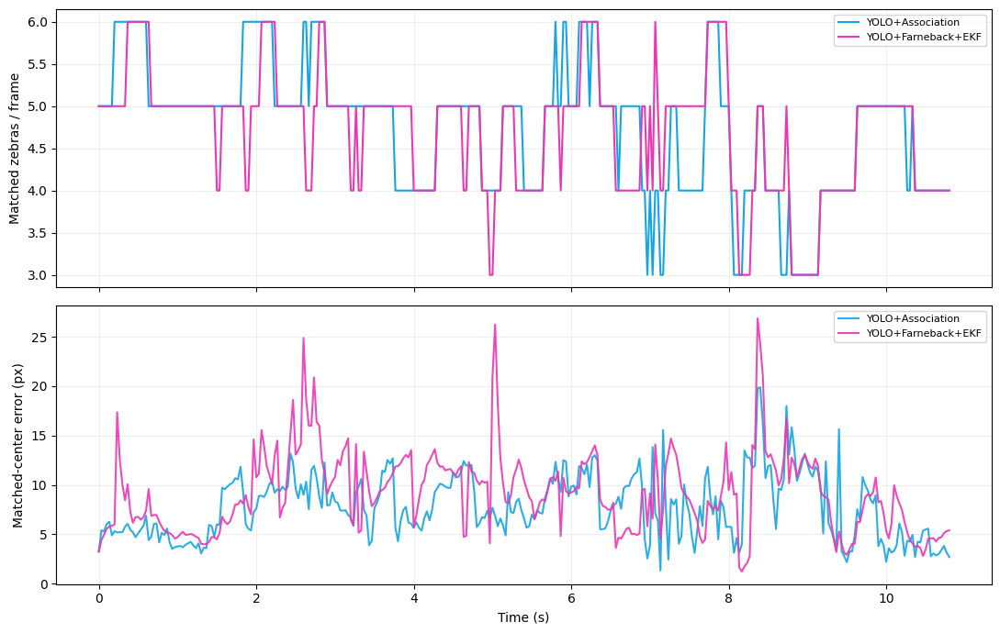

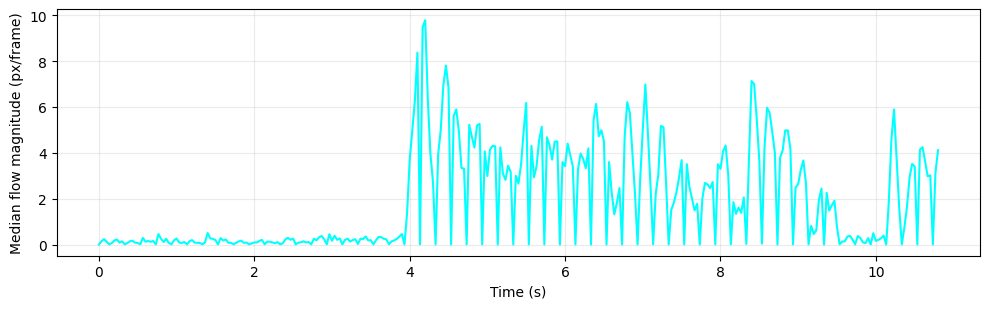

In [16]:
metrics = pd.DataFrame([score_baseline.summary(), score_fusion.summary()])
metrics.insert(1, "sequence", SELECTED["name"])
metrics["frames"] = len(frame_ids_processed)
metrics["duration_seconds"] = len(frame_ids_processed) / SELECTED["fps"]
metrics["end_to_end_ms_per_frame"] = float(np.mean(per_frame_times))
metrics["end_to_end_fps"] = 1000 / max(float(np.mean(per_frame_times)), 1e-6)
metrics["source_fps"] = SELECTED["fps"]
metrics["fps_source"] = SELECTED["fps_source"]
metrics["ground_truth_available"] = HAS_GT
metrics["simulated_detection_dropout"] = SIMULATE_DETECTION_DROPOUT
metrics["dropped_measurement_frames"] = sum(dropout_flags)
display(metrics.round(4))
metrics.to_csv(RESULTS / "tracking_summary.csv", index=False)
rows = pd.DataFrame(score_baseline.frames + score_fusion.frames)
rows.to_csv(RESULTS / "per_frame_metrics.csv", index=False)
pd.DataFrame(track_rows).to_csv(RESULTS / "fusion_trajectories.csv", index=False)
pd.DataFrame({"frame": frame_ids_processed,
              "end_to_end_ms": per_frame_times,
              "median_dense_flow_px": flow_magnitudes,
              "raw_yolo_detection_count":detector_counts,
              "simulated_dropout":dropout_flags}).to_csv(
              RESULTS / "processing_times_and_motion.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for evaluator in (score_baseline, score_fusion):
    chart_color = (VIS_COLORS_RGB["baseline"] if evaluator is score_baseline
                   else VIS_COLORS_RGB["fusion"])
    chart_color = np.array(chart_color)/255
    frame_df = pd.DataFrame(evaluator.frames)
    values = frame_df["TP"] if HAS_GT else frame_df["predictions"]
    axes[0].plot(np.arange(len(frame_df)) / SELECTED["fps"], values, label=evaluator.label, color=chart_color)
    axes[1].plot(np.arange(len(frame_df)) / SELECTED["fps"],
                 frame_df["mean_CLE_px_matched"], label=evaluator.label,
                 color=chart_color, alpha=0.9)
axes[0].set_ylabel("Matched zebras / frame" if HAS_GT else "Predicted zebras / frame")
axes[1].set_ylabel("Matched-center error (px)" if HAS_GT else "No GT: CLE undefined")
axes[1].set_xlabel("Time (s)")
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "tracking_per_frame.png", dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(np.arange(len(flow_magnitudes)) / SELECTED["fps"], flow_magnitudes,
        color=np.array(VIS_COLORS_RGB["flow"])/255)
ax.set(xlabel="Time (s)", ylabel="Median flow magnitude (px/frame)")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS / "dense_motion_magnitude.png", dpi=170)
plt.show()

## Per-target state trajectories and localization error

After inference, one annotated zebra is chosen for reference plotting according to temporal coverage. Each candidate prediction is paired to the reference only after framewise IoU matching exceeds $0.5$. These associations are diagnostic and never reinitialize or adjust the EKF. Frames without valid matches are excluded from paired localization RMSE and counted separately through coverage and missed-target statistics.

For valid matched frames $S$, the center-coordinate error is summarized as

$$\operatorname{RMSE}=\sqrt{|S|^{-1}\sum_{t\in S}\lVert\hat{\mathbf c}_t-\mathbf c_t^{GT}\rVert_2^2}.$$

The plotted flow-only location is a one-step displacement proxy originating from the estimated track position, not a separately initialized flow tracker. Comparisons of matched-pair RMSE should therefore be read alongside temporal coverage and identity-continuity metrics.


,reference_gt_id,annotated_frames,matched_frames,matching_coverage,paired_flow_vs_ekf_frames,raw_flow_proxy_RMSE_px_paired,EKF_posterior_RMSE_px_paired,EKF_posterior_RMSE_px_all_matched
0,4,325,311,0.957,309,7.172,6.912,6.891


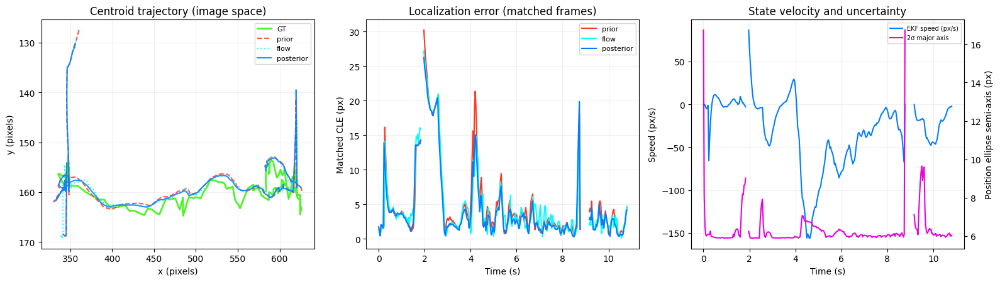

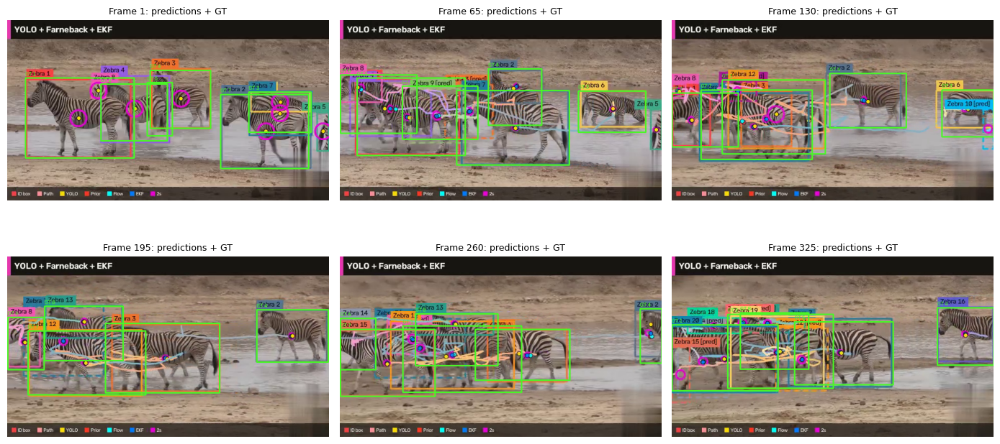

In [17]:
# Choose the reference identity after inference for error diagnostics.
seq_gt = SELECTED["annotations"]
valid_ids = []
for gid, group in seq_gt.groupby("id"):
    covered = sum(int(f) in set(frame_ids_processed) for f in group.frame.astype(int))
    if covered:
        valid_ids.append((covered, int(gid)))
TARGET_DIAGNOSTIC_GT_ID = max(valid_ids)[1] if valid_ids else None

def numeric_center(row, prefix):
    return np.array([row[prefix+"_cx"], row[prefix+"_cy"]], dtype=float)

per_frame_gt = {int(f):scale_gt(grp, SX, SY)
                for f, grp in SELECTED["annotations"].groupby("frame")}
rows_target = []
tracks_by_frame = defaultdict(list)
for row in track_rows:
    tracks_by_frame[int(row["frame"])].append(row)
for f in frame_ids_processed:
    ref = next((g for g in per_frame_gt.get(f, [])
                if g["id"] == TARGET_DIAGNOSTIC_GT_ID), None)
    if ref is None:
        continue
    gt_center = center(ref["box"])
    predictions = tracks_by_frame.get(f, [])
    matched = match_frame([{"box":np.array([t["x"], t["y"],t["width"],t["height"]])}
                           for t in predictions], [ref])
    observation = predictions[matched[0][0]] if matched else None
    data = {"frame":int(f), "time_seconds":(frame_ids_processed.index(f)/SELECTED["fps"]),
            "gt_id":int(TARGET_DIAGNOSTIC_GT_ID), "gt_cx":float(gt_center[0]),
            "gt_cy":float(gt_center[1]), "matched":bool(observation),
            "predicted_track_id":int(observation["track_id"]) if observation else np.nan,
            "iou":float(matched[0][2]) if matched else np.nan}
    for label in ("prior", "flow", "posterior", "detection"):
        cx = observation.get(f"{label}_cx",np.nan) if observation else np.nan
        cy = observation.get(f"{label}_cy",np.nan) if observation else np.nan
        data[f"{label}_cx"] = cx; data[f"{label}_cy"] = cy
        data[f"cle_{label}_px"] = (float(np.hypot(cx-gt_center[0],cy-gt_center[1]))
                                       if np.isfinite(cx) and np.isfinite(cy) else np.nan)
    for label in ("speed_px_s","heading_deg","turn_rate_deg_s","sigma_major_px",
                  "sigma_minor_px","flow_accepted","misses"):
        data[label]=observation.get(label,np.nan) if observation else np.nan
    rows_target.append(data)

target_df = pd.DataFrame(rows_target)
if not target_df.empty:
    target_df.to_csv(RESULTS/"target_state_diagnostics.csv",index=False)
    paired = target_df.dropna(subset=["cle_flow_px","cle_posterior_px"])
    def error_rmse(values):
        return float(np.sqrt(np.mean(np.asarray(values,dtype=float)**2))) if len(values) else np.nan
    gt_count = len(target_df)
    target_results = {
        "reference_gt_id":TARGET_DIAGNOSTIC_GT_ID,
        "annotated_frames":gt_count,
        "matched_frames":int(target_df.matched.sum()),
        "matching_coverage":float(target_df.matched.mean()),
        "paired_flow_vs_ekf_frames":len(paired),
        "raw_flow_proxy_RMSE_px_paired":error_rmse(paired.cle_flow_px),
        "EKF_posterior_RMSE_px_paired":error_rmse(paired.cle_posterior_px),
        "EKF_posterior_RMSE_px_all_matched":error_rmse(target_df.cle_posterior_px.dropna()),
    }
    pd.DataFrame([target_results]).to_csv(RESULTS/"target_error_summary.csv",index=False)
    display(pd.DataFrame([target_results]).round(3))
    fig, axes = plt.subplots(1,3,figsize=(16,4.6))
    axes[0].plot(target_df.gt_cx,target_df.gt_cy,label="GT",color=np.array(VIS_COLORS_RGB["ground_truth"])/255,lw=2)
    for key, style in (("prior","--"),("flow",":"),("posterior","-")):
        axes[0].plot(target_df[f"{key}_cx"],target_df[f"{key}_cy"],style,label=key,alpha=.85,
                    color=np.array(VIS_COLORS_RGB[{"prior":"prediction",
                         "flow":"flow","posterior":"posterior"}[key]])/255)
    axes[0].invert_yaxis();axes[0].set_title("Centroid trajectory (image space)")
    axes[0].set(xlabel="x (pixels)",ylabel="y (pixels)");axes[0].legend(fontsize=8)
    for key in ("prior","flow","posterior"):
        axes[1].plot(target_df.time_seconds,target_df[f"cle_{key}_px"],label=key,
                     color=np.array(VIS_COLORS_RGB[{"prior":"prediction",
                         "flow":"flow","posterior":"posterior"}[key]])/255)
    axes[1].set(xlabel="Time (s)",ylabel="Matched CLE (px)",title="Localization error (matched frames)")
    axes[1].legend(fontsize=8)
    axes[2].plot(target_df.time_seconds,target_df.speed_px_s,label="EKF speed (px/s)",
                 color=np.array(VIS_COLORS_RGB["posterior"])/255)
    ax2=axes[2].twinx()
    ax2.plot(target_df.time_seconds,target_df.sigma_major_px,color=np.array(VIS_COLORS_RGB["uncertainty"])/255,label="2σ major axis")
    axes[2].set(xlabel="Time (s)",ylabel="Speed (px/s)",title="State velocity and uncertainty")
    ax2.set_ylabel("Position ellipse semi-axis (px)")
    handles1, labels1=axes[2].get_legend_handles_labels()
    handles2, labels2=ax2.get_legend_handles_labels()
    axes[2].legend(handles1+handles2,labels1+labels2,fontsize=7)
    for a in axes: a.grid(alpha=.18)
    fig.tight_layout();fig.savefig(RESULTS/"target_state_diagnostics.png",dpi=160);plt.show()
else:
    print("No diagnostic GT ID overlaps the processed interval.")

# Render annotated reference overlays only after tracking has completed.
cap = cv2.VideoCapture(str(OUTPUT_VIDEOS["fusion"]))
snapshots = []
for relative in np.unique(np.linspace(0,len(frame_ids_processed)-1,min(6,len(frame_ids_processed)),dtype=int)):
    cap.set(cv2.CAP_PROP_POS_FRAMES,int(relative))
    ok, rendered = cap.read()
    if not ok: continue
    fid = frame_ids_processed[int(relative)]
    reference = per_frame_gt.get(fid,[])
    for g in reference:
        x,y,w,h=np.rint(g["box"]).astype(int)
        cv2.rectangle(rendered,(x,y),(x+w,y+h),VIS_COLORS_BGR["ground_truth"],2)
        cv2.putText(rendered,f"GT {g['id']}",(x,max(13,y-4)),cv2.FONT_HERSHEY_SIMPLEX,
                    .36,VIS_COLORS_BGR["ground_truth"],1,cv2.LINE_AA)
    snapshots.append((fid,cv2.cvtColor(rendered,cv2.COLOR_BGR2RGB)))
cap.release()
if snapshots:
    fig,axes=plt.subplots(2,3,figsize=(14,7.3))
    for ax in axes.flat: ax.axis("off")
    for ax,(fid,arr) in zip(axes.flat,snapshots):
        ax.imshow(arr);ax.set_title(f"Frame {fid}: predictions + GT",fontsize=9)
    fig.tight_layout();fig.savefig(RESULTS/"ground_truth_overlay_snapshots.png",dpi=140);plt.show()

## 15. Frame visualization and export artifacts

The comparison MP4 is previewed through `Video(str(path), ...)` after H.264 encoding validation. A multi-timepoint montage samples representative positions along the exported video. Machine-readable files include aggregate and framewise metrics, trajectories, timing, motion magnitude, and run configuration.

The final ZIP bundles videos, figures, numeric tables, and diagnostic records; original dataset archives and extracted source frames are excluded to avoid duplicating raw input data.


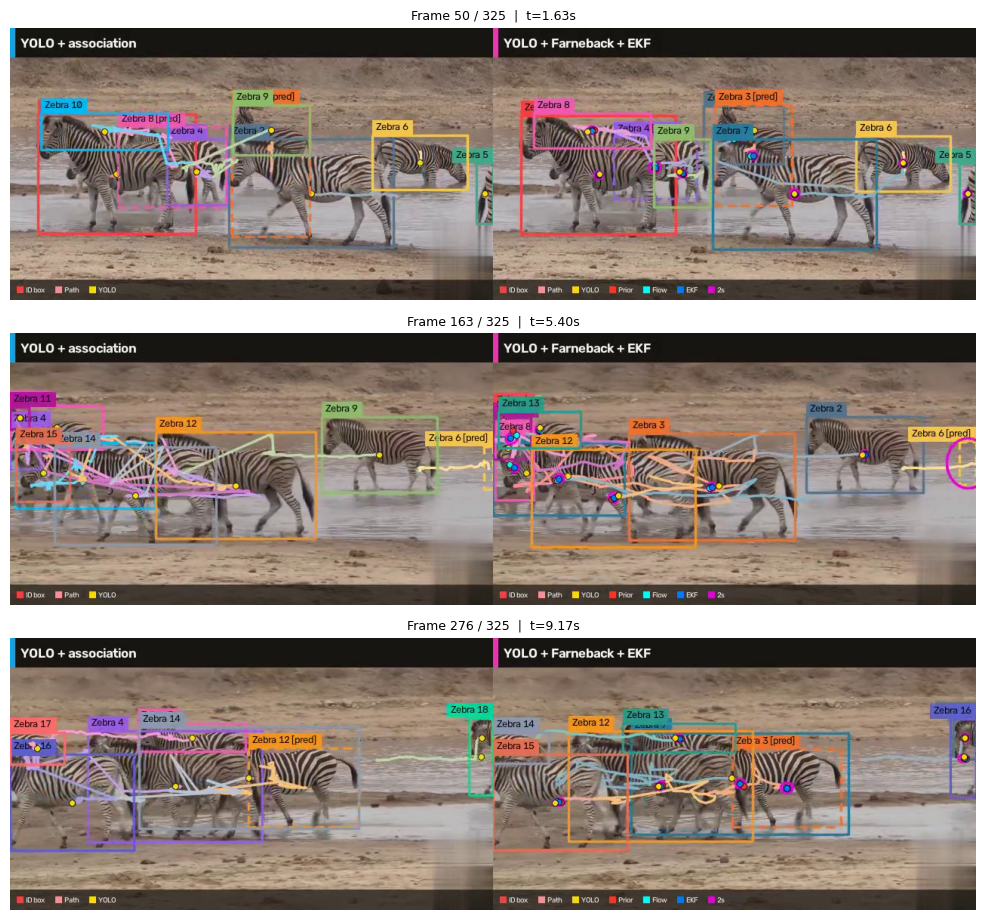

Comparison video: zebra_comparison_raw_h264.mp4


Output ZIP: /content/animaltrack_zebra_tracking/AnimalTrack_Zebra_EKF_Farneback_YOLO_results.zip
Archive size (MB): 15.19


In [18]:
def sample_montage(video_path, samples=(0.15, 0.50, 0.85)):
    cap = cv2.VideoCapture(str(video_path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    snapshots = []
    for pct in samples:
        idx = int(np.clip(round((total-1) * pct), 0, max(0, total-1)))
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, image = cap.read()
        if ok:
            snapshots.append((idx, cv2.cvtColor(image, cv2.COLOR_BGR2RGB)))
    cap.release()
    if not snapshots:
        return None
    fig, axes = plt.subplots(len(snapshots), 1, figsize=(12, 3.1 * len(snapshots)))
    axes = np.atleast_1d(axes)
    for axis, (idx, image) in zip(axes, snapshots):
        axis.imshow(image)
        axis.axis("off")
        axis.set_title(f"Frame {idx+1} / {total}  |  t={idx/SELECTED['fps']:.2f}s", fontsize=9)
    fig.tight_layout()
    path = RESULTS / "tracking_montage.png"
    fig.savefig(path, dpi=135)
    plt.show()
    return path

montage_file = sample_montage(OUTPUT_VIDEOS["comparison"])

print("Comparison video:", OUTPUT_VIDEOS["comparison"].name)
display(Video(str(OUTPUT_VIDEOS["comparison"]), embed=True, width=900, mimetype="video/mp4"))

configuration = {
    "dataset": "AnimalTrack / Zebra",
    "dataset_url": "https://hengfan2010.github.io/projects/AnimalTrack/download.html",
    "selected_sequence": SELECTED["name"],
    "source_fps": SELECTED["fps"],
    "fps_origin": SELECTED["fps_source"],
    "processed_frames": len(frame_ids_processed),
    "processed_duration_seconds": len(frame_ids_processed) / SELECTED["fps"],
    "model": YOLO_MODEL,
    "model_class": "zebra",
    "detection_confidence": YOLO_CONFIDENCE,
    "max_frame_width": MAX_FRAME_WIDTH,
    "optical_flow": "Farneback (dense), robust central-ROI median + MAD filtering",
    "state_model": "7D nonlinear image-space CTRV EKF",
    "association": "Hungarian IoU/normalized center distance",
    "reference_use": "evaluation only" if HAS_GT else "not available",
    "ground_truth_available": HAS_GT,
    "identity_metric_note": "global IDF1 proxy; not official TrackEval IDF1",
    "sparse_lk_flow": "two-frame diagnostic only; not used by EKF",
    "simulated_detection_dropout":SIMULATE_DETECTION_DROPOUT,
    "dropout_relative_start":DROPOUT_START_INDEX,
    "dropout_relative_end":DROPOUT_END_INDEX,
    "position_uncertainty": "2-sigma covariance ellipse; heuristic covariance",
}
(RESULTS / "run_config.json").write_text(json.dumps(configuration, indent=2), encoding="utf-8")

readme = ("AnimalTrack Zebra: YOLO/Farneback/EKF tracking\n"
          f"Ground truth available: {HAS_GT}.\n"
          "When missing, reference-based metrics are NaN, not zero or pseudo-label values.\n"
          "tracking_summary.csv: aggregate association and localization metrics.\n"
          "per_frame_metrics.csv: thresholded IoU matching, per frame.\n"
          "fusion_trajectories.csv: predicted track IDs and boxes.\n"
          "processing_times_and_motion.csv: end-to-end timing and flow magnitude.\n"
          "global_IDF1_proxy is not the official IDF1 implementation.\n"
          "target_state_diagnostics.csv includes separate prior, flow, and posterior observations.\n"
          "target_error_summary.csv gives paired, matched-only RMSE; coverage is reported.\n"
          "Sparse LK is a standalone diagnostic, not part of the Farneback-EKF inference path.\n"
          "sparse_lk_feature_diagnostics.csv records feature counts and replenishment events.\n"
          "Simulated detection dropout is disabled unless configured before tracking.\n")
(RESULTS / "README.txt").write_text(readme, encoding="utf-8")
zip_path = ROOT / "AnimalTrack_Zebra_EKF_Farneback_YOLO_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(RESULTS.rglob("*")):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(RESULTS.parent))
print("Output ZIP:", zip_path)
print("Archive size (MB):", round(zip_path.stat().st_size / 1e6, 2))

## 16. Result interpretation and model limitations

The numerical results produced by the execution cells should be interpreted jointly rather than from a single score:

- **Localization and coverage:** compare matched CLE and IoU together with recall and false negatives. Low center error on a small set of surviving tracks does not imply high overall tracking quality.
- **Track identity:** inspect ID-change counts and the reported `global_IDF1_proxy` alongside tracking footage. The proxy is not official TrackEval IDF1 or HOTA.
- **Motion estimation:** Farnebäck measures apparent image displacement, potentially combining animal movement with camera movement and background texture. Central ROI cropping and robust filtering reduce sensitivity but cannot fully isolate the target.
- **State dynamics:** the image-space CTRV model approximates smooth center trajectories; sudden turns, articulation, occlusion, and rapid scale changes can violate its assumptions. EKF covariance is heuristic, so the $2\sigma$ ellipse is a diagnostic of internal uncertainty rather than validated prediction coverage.
- **Detector and matching failure:** small or overlapping zebras can reduce YOLO recall. Geometric Hungarian matching may exchange identities when similarly shaped animals overlap, particularly without appearance embeddings.
- **Computation:** reported processing ms/frame captures the sequential inference pipeline but excludes notebook rendering and video transcoding. Compare measured throughput with source FPS before drawing real-time conclusions.
- **Temporal metadata:** use the recorded frame-rate source. A fallback 30 FPS is an explicit assumption when metadata is unavailable; the notebook does not interpolate extra frames.

**Interpretation boundary:** the notebook source does not itself establish numerical superiority of the fusion tracker. Conclusions must be based on `tracking_summary.csv`, `per_frame_metrics.csv`, timing outputs, and saved visualizations after execution. If reference labels are missing, only qualitative trajectory inspection and reference-free timing/counts are supported.

**Methods cited:** Zhang et al., *AnimalTrack: A Benchmark for Multi-Animal Tracking in the Wild*; Farnebäck, *Two-Frame Motion Estimation Based on Polynomial Expansion*; Kalman, *A New Approach to Linear Filtering and Prediction Problems*.

Additional visual diagnostics include first-frame detection/reference alignment, separate sparse LK flow, feature replenishment, EKF state priors/posteriors, covariance ellipses, matched-pair trajectory RMSE, optional detector-dropout conditions, and reference-only montage frames. Identity colors are deterministic; OpenCV drawing uses BGR channel ordering.
